In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import itertools
import matplotlib
from matplotlib import cm
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, describe, mode, fisher_exact
import scipy as sp
import scipy.stats as stats
from scipy.spatial.distance import jaccard, euclidean, cosine, pdist
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.metrics import pairwise_distances
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.decomposition import NMF, non_negative_factorization
from collections import Counter
from scipy.stats import hypergeom
from scipy.stats.mstats import gmean
from scipy.cluster import hierarchy
import squarify
try:
    import piplite
    await piplite.install(['ipywidgets'])
except ImportError:
    pass
import ipywidgets as widgets
import json
from subprocess import Popen, PIPE
import requests

today = date.today()

**TSS Coordinates for Genes in Genesets**

In [30]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'

# geneset paths
c5go_f = datadir + 'MSigDB/c5.go.v2023.1.Hs.symbols.gmt'
c5gobp_f = datadir + 'MSigDB/c5.go.bp.v2023.1.Hs.symbols.gmt'
hallmark_f =  datadir + 'MSigDB/h.all.v7.5.1.symbols.gmt'
c2_f = datadir + 'MSigDB/c2.all.v7.5.1.symbols.gmt'

# gene path
gene_f = datadir + 'GREATv4/GREATv4.genes.hg38.tsv'

In [3]:
# build dictionary of genes mapping to coordinates
# also build dictionary of genes mapping to strand (direction)
f = open(gene_f)

header = f.readline()

gene2coords = {}
gene2strand = {}
for line in f.readlines():
    line = line.strip().split('\t')
    gene = line[4]
    coord = [line[1], line[2]]
    strand = [line[3]]
    if gene not in gene2coords:
        gene2coords[gene] = [coord]
        gene2strand[gene] = [strand]
    else:
        gene2coords[gene].append(coord)
        gene2strand[gene].append(strand)
f.close()

In [52]:
# build dictionary of genesets mapping to a list of genes
geneset2genes = {}
for gs_f in [c5gobp_f]:  # hallmark_f, c2_f, c5go_f
    f = open(gs_f)
    for line in f.readlines():
        line = line.strip().split('\t')
        gs = line[0]
        genes = line[2:]
        geneset2genes[gs] = genes
    f.close()

In [53]:
# build dictionary of genes mapping to a list of genesets
gene2genesets = {}
for gs in geneset2genes.keys():
    genes = geneset2genes[gs]
    for g in genes:
        if g not in gene2genesets:
            gene2genesets[g] = np.array([gs])
        else:
            gene2genesets[g] = np.append(gene2genesets[g], np.array([gs]))

In [54]:
len(gene2genesets), len(geneset2genes)#, len(gene2coords), len(gene2strand)

(17890, 7751)

In [7]:
# get the full list of genes
genes_in_great4 = np.sort(list(gene2coords.keys()))

In [8]:
# # get TSS bp coordinates for genes in genesets
# genes_in_great4_coords = []

# for gene in genes_in_great4:
#     if gene in gene2coords:
#         coords = gene2coords[gene]
#         if ((len(coords) == 1) & 
#             (coords[0][0][-1] != 'M') & 
#             (len(gene2strand[gene]) == 1)):
#             genes_in_great4_coords.append(
#                 np.append(
#                     np.append(
#                         coords[0], 
#                         gene
#                     ), 
#                     gene2strand[gene][0]
#                 )
#             )
            
# genes_in_great4_coords = np.array(genes_in_great4_coords)

In [9]:
# get TSS bp coordinates for genes in genesets
genes_in_great4_coords = np.loadtxt(gene_f, delimiter='\t', dtype=str)
genes_in_great4_coords = genes_in_great4_coords[:, [1, 2, 4, 3]]

**Assign Basal Regions to Each Gene**

In [10]:
genes_in_great4_coords = np.hstack(
    (
        genes_in_great4_coords, 
        np.zeros((genes_in_great4_coords.shape[0], 2), dtype=str)
    )
)

In [11]:
# define basal region distances
basal_up = 5000
basal_down = 1000

In [12]:
# define basal regions for each gene
for gene in genes_in_great4_coords:
    strand = gene[3]
    if strand == '+':
        gene[4] = str(np.max([0, int(gene[1]) - basal_up]))
        gene[5] = str(int(gene[1]) + basal_down)
    if strand == '-':
        gene[4] = str(np.max([0, int(gene[1]) - basal_down]))
        gene[5] = str(int(gene[1]) + basal_up)

**Sorting genes**

In [13]:
# genes already sorted

# # sort genes by genomic location for easy basal domain extension
# ind_order = np.array([], dtype=int)
# chrm_order = np.unique(genes_in_great4_coords[:, 0])
# for chrm in chrm_order:
#     chrm_inds = np.where(genes_in_great4_coords[:, 0] == chrm)[0]
# #     basal_start_bp = genes_in_great4_coords[chrm_inds, 4].astype(int)
# #     chrm_inds_ordered = chrm_inds[np.argsort(basal_start_bp)]
#     start_bp = genes_in_great4_coords[chrm_inds, 1].astype(int)
#     chrm_inds_ordered = chrm_inds[np.argsort(start_bp)]
#     ind_order = np.append(ind_order, chrm_inds_ordered)
    
# genes_in_great4_coords = genes_in_great4_coords[ind_order]

**Extending Basal Domain**

In [14]:
genes_in_great4_coords = np.hstack(
    (
        genes_in_great4_coords, 
        np.zeros((genes_in_great4_coords.shape[0], 2), dtype=str)
    )
)

In [15]:
genes_in_great4_coords[[3,4,5,6]]

array([['chr1', '925737', 'SAMD11', '+', '920737', '926737', '', ''],
       ['chr1', '959290', 'NOC2L', '-', '958290', '964290', '', ''],
       ['chr1', '960586', 'KLHL17', '+', '955586', '961586', '', ''],
       ['chr1', '966496', 'PLEKHN1', '+', '961496', '967496', '', '']],
      dtype='<U687')

In [16]:
# define extension distance
extension_dist = 1000000

In [17]:
for i in range(len(genes_in_great4_coords)):
    chr_ind = 0
    start_ind = 4
    end_ind = 5
    
    extended_start_ind = 6
    extended_end_ind = 7
    
    gene = genes_in_great4_coords[i]
    gene_chr = gene[chr_ind]
    gene_start = int(gene[start_ind])
    gene_end = int(gene[end_ind])
    
    # find neighboring genes
    if i != 0:
        left_gene = genes_in_great4_coords[i - 1]
    else:
        left_gene = genes_in_great4_coords[-1]
    if i != len(genes_in_great4_coords) - 1:
        right_gene = genes_in_great4_coords[i + 1]
    else:
        right_gene = genes_in_great4_coords[0]
    
    left_gene_chr = left_gene[chr_ind]
    left_gene_start = int(left_gene[start_ind])
    left_gene_end = int(left_gene[end_ind])
    
    right_gene_chr = right_gene[chr_ind]
    right_gene_start = int(right_gene[start_ind])
    right_gene_end = int(right_gene[end_ind])
    
    
    # extend left domain of gene
    # opposite start genes next to each other
    if ((right_gene_chr == gene_chr) & (right_gene_start <= gene_start)):
        left_extended = gene_start
    elif left_gene_chr != gene_chr:  # different chromosome
        left_extended = np.max([0, gene_start - extension_dist])
    else:  # same chromosome
        left_extended = np.max([
            np.min([left_gene_end, gene_start]),
            gene_start - extension_dist
        ])    
    genes_in_great4_coords[i, extended_start_ind] = str(left_extended)
    
    # extend right domain of gene
    # opposite start genes next to each other
    if ((left_gene_chr == gene_chr) & (left_gene_end >= gene_end)):
        right_extended = gene_end
    elif right_gene_chr != gene_chr:  # different chromosome
        right_extended = gene_end + extension_dist
    else:  # same chromosome
        right_extended = np.min([
            np.max([right_gene_start, gene_end]),
            gene_end + extension_dist
        ])
    genes_in_great4_coords[i, extended_end_ind] = str(right_extended)    

**Saving**

In [18]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'

In [19]:
# out_f = datadir + 'GREATv4/GREATv4_genes.TSS_bp.gene.strand.basal_5kbup_1kbdown.extended_1000kb.CT20230601.bed'
# np.savetxt(out_f, genes_in_great4_coords, fmt='%s', delimiter='\t')

In [20]:
# out_f = datadir + 'GREATv4/GREATv4_genes.extended_domain_1000kb.gene.CT20230601.bed'
# np.savetxt(out_f, genes_in_great4_coords[:, [0, 6, 7, 2]], fmt='%s', delimiter='\t')

**Generate bed file from search spaces**

In [3]:
datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert/'

In [4]:
for order in [4, 5, 6, 7, 8, 9, 10, 11]:
    print(order)
    search_space_file = datadir + 'hilbert_regions_order_{}_CT20230606.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.npz'.format(order)
    search_space_coords = np.load(search_space_file)['coordinates']
    search_space_ori_inds = np.load(search_space_file)['original_inds']
    
    search_space_out = np.hstack((search_space_coords, search_space_ori_inds.reshape(-1, 1)))
    search_space_out_file = datadir + 'hilbert_regions_order_{}_CT20230606.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.bed'.format(order)
    np.savetxt(search_space_out_file, search_space_out, fmt='%s', delimiter='\t')

4
5
6
7
8
9
10
11


In [53]:
# sort and map
"""
sort-bed hilbert_regions_order_4_CT20230606.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.bed > hilbert_regions_order_4_CT20230606.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.sorted.bed
bedmap --echo --echo-map-id hilbert_regions_order_4_CT20230606.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.sorted.bed GREATv4/GREATv4_genes.extended_domain_1000kb.gene.CT20230601.sorted.bed > hilbert_regions_order_4_CT20230606.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.sorted.GREATv4_genes_extended_domain_1000kb_mapped.bed
"""

In [22]:
# # sanity check: sorting shouldn't change ordering
# for order in [4, 5, 6, 7, 8, 9, 10, 11]:
#     search_space_file = datadir + 'hilbert_regions_order_{}_CT20230606.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.bed'.format(order)
#     x = np.loadtxt(search_space_file, delimiter='\t', dtype=str)
    
#     search_space_file = datadir + 'hilbert_regions_order_{}_CT20230606.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.sorted.bed'.format(order)
#     y = np.loadtxt(search_space_file, delimiter='\t', dtype=str)
    
#     x_i = x[:, 3].astype(int)
#     y_i = y[:, 3].astype(int)
    
#     if len(np.where(y_i != x_i)[0]) > 0:
#         print(order)

**Parse mapped file and populate binary Geneset x Region matrix**

In [55]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
in_f = datadir + 'GREATv4/GREATv4_genes.TSS_bp.gene.strand.basal_5kbup_1kbdown.extended_1000kb.CT20230601.bed'
genes_in_great4_coords = np.loadtxt(in_f, dtype=str, delimiter='\t')

In [56]:
# gene_order = genes_in_great4_coords[:, 2]
# geneset_order = np.array(list(geneset2genes.keys())) # used for just C5GO

gene_order = np.unique(genes_in_great4_coords[:, 2])
geneset_order = np.unique(list(geneset2genes.keys())) # used for (C5GO, Hallmark, and C2) and (C5GOBP) 

In [57]:
gene_order.shape, geneset_order.shape

((18774,), (7751,))

In [58]:
# for each order, create a search space X geneset binary matrix

datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert/'
for order in [4, 5, 6, 7, 8, 9, 10, 11]:
    
    mapped_f = datadir + 'hilbert_regions_order_{}_CT20230606.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.sorted.GREATv4_genes_extended_domain_1000kb_mapped.bed'.format(order)

    f = open(mapped_f)
    lines = f.readlines()
    f.close()

    # binary matrix for genes located in each search space region
    search_space_geneset_bin = np.zeros((len(lines), len(geneset_order)), dtype=int)
    
    print(order, search_space_geneset_bin.shape)

    # for each search space region, populate binary matrix
    for i in range(len(lines)):
        line = lines[i]
        line = re.split('[\t|;]', line.strip())
        mapped_genes = line[4:]

        mapped_gene_genesets = np.array([])
        for g in mapped_genes:
            if g in gene2genesets:
                mapped_gene_genesets = np.append(mapped_gene_genesets, gene2genesets[g])
        mapped_gene_genesets = np.unique(mapped_gene_genesets)

        gs_inds = np.where(np.isin(geneset_order, mapped_gene_genesets))[0]

        search_space_geneset_bin[i, gs_inds] = 1
        
        
    out_f = datadir + 'hilbert_regions_order_{}.search_space_top_1000_no_overlap.mapped_extended_domain_GREATv4_gene_c5GOBP_genesets.bin.CT20230608.npy'.format(order)
    np.save(out_f, search_space_geneset_bin)

4 (2725, 7751)
5 (8648, 7751)
6 (18133, 7751)
7 (27078, 7751)
8 (31970, 7751)
9 (33547, 7751)
10 (33892, 7751)
11 (33975, 7751)


In [25]:
# datadir = '/home/ctrader/region_similarity/data/rank_based/'
# out_f = datadir + 'regions_25kb.search_space_top_1000_no_overlap.mapped_extended_domain_GREATv4_gene_h_c2_c5GO_genesets.bin.CT20230601.npy'

# np.save(out_f, search_space_geneset_bin)

In [23]:
# datadir = '/home/ctrader/region_similarity/data/rank_based/'
# out_f = datadir + 'regions_25kb.search_space_top_1000_no_overlap.mapped_extended_domain_GREATv4_gene_c5GOBP_genesets.bin.CT20230607.npy'

# np.save(out_f, search_space_geneset_bin)

In [57]:
# datadir = '/home/ctrader/region_similarity/data/rank_based/'
# in_f = datadir + 'regions_25kb.search_space_top_1000_no_overlap.mapped_extended_domain_GREATv4_gene_h_c2_c5GO_genesets.bin.CT20230601.npy'

# search_space_geneset_bin = np.load(in_f)

In [72]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
in_f = datadir + 'regions_25kb.search_space_top_1000_no_overlap.mapped_extended_domain_GREATv4_gene_c5GOBP_genesets.bin.CT20230607.npy'

search_space_geneset_bin = np.load(in_f)

Get query regions

In [74]:
search_space_geneset_bin.shape

(32749, 7751)

In [75]:
gs_region_counts = np.sum(search_space_geneset_bin, axis=0)
num_regions = search_space_geneset_bin.shape[0]

In [76]:
def production_post_request(coords, scale):
    prod_url = 'https://explore.altius.org:5001/narration'
    post_body = {
        'location': coords,
        'factors': '[' + ','.join(np.arange(34).astype(str)) + ']',
        'roiURL': 'False',
        'scale': scale,
        'queryFactorThresh': '0.5',
        'numSimilarRegions': '100',
        'regionMethod': 'sliding_window'
    }
    response = requests.post(prod_url, json=post_body)
    return response

def query_sim_hypergeom(region_inds, N=20, M=num_regions, n=gs_region_counts, geneset_order=geneset_order):
    k = np.sum(search_space_geneset_bin[region_inds], axis=0)
    inds_to_test = np.where(k)[0]
    
    test = hypergeom.sf(k[inds_to_test], M, n[inds_to_test], N)
    tested_genesets = geneset_order[inds_to_test]
    return tested_genesets, test

In [77]:
dl = 3

query_coords = 'chr10:100141000-100166000' # pretty good, dl=1
# query_coords = 'chr4:173514000-173539000' # good at dl=7
query_coords = 'chr14:28755875-28780934' # decent at dl=3, dl=5
# query_coords = 'chr2:88112000-88137000' # great at dl=1
scale = 25

response = production_post_request(query_coords, scale)
query_full_data = json.loads(response.text)

query_sim_region_inds = []
query_sim_region_coords = []
for i in range(1, len(query_full_data[0])):
    coord = re.split('[:-]', query_full_data[dl - 1][i]['coordinates'])
    query_sim_region_coords.append(coord)
    query_sim_region_inds.append(query_full_data[dl - 1][i]['region_ind'])

In [78]:
for c in query_sim_region_coords:
    print(c[0] + '\t' + c[1] + '\t' + c[2])

chr14	56794000	56819000
chr3	147384000	147409000
chr13	112052000	112077000
chr12	113463000	113488000
chr7	96997000	97022000
chr1	156416000	156441000
chr1	90704000	90729000
chr15	52786000	52811000
chr2	222292000	222317000
chr7	155440000	155465000
chr5	88671000	88696000
chr13	99953000	99978000
chr14	36503000	36528000
chr2	104846000	104871000
chr8	9895000	9920000
chr6	99594000	99619000
chr15	59990000	60015000
chr3	181701000	181726000
chr4	146632000	146657000
chr4	84480000	84505000
chr15	89358000	89383000
chr9	123999000	124024000
chr6	98820000	98845000
chr6	50824000	50849000
chr5	77624000	77649000
chr20	22558000	22583000
chr2	44923000	44948000
chr13	78586000	78611000
chr8	54449000	54474000
chr2	118829000	118854000
chr7	1221000	1246000
chr7	20772000	20797000
chr4	8854000	8879000
chr6	100446000	100471000
chr4	110610000	110635000
chrX	25001000	25026000
chr5	51376000	51401000
chr3	147353000	147378000
chr2	70883000	70908000
chr20	21502000	21527000
chr10	101219000	101244000
chr2	176063000	176088

In [79]:
query_tested_gs, query_tested_gs_pval = query_sim_hypergeom(query_sim_region_inds, N=100)

In [80]:
c = 0
sig_gs = []
sort_order = np.argsort(query_tested_gs_pval)
for i, j in zip(query_tested_gs[sort_order], query_tested_gs_pval[sort_order]):
    if (j * len(geneset_order)) < 0.05:
        print(i + '\t' + str(j))
        c += 1
        sig_gs.append(i)

GOBP_PATTERN_SPECIFICATION_PROCESS	1.76973965986814e-28
GOBP_POSITIVE_REGULATION_OF_TRANSCRIPTION_BY_RNA_POLYMERASE_II	1.9730433918536662e-26
GOBP_POSITIVE_REGULATION_OF_RNA_METABOLIC_PROCESS	8.058216152086649e-24
GOBP_POSITIVE_REGULATION_OF_MACROMOLECULE_BIOSYNTHETIC_PROCESS	2.4498430184018952e-23
GOBP_CENTRAL_NERVOUS_SYSTEM_DEVELOPMENT	1.0063691801152127e-21
GOBP_HEAD_DEVELOPMENT	1.9186306726309477e-20
GOBP_CELL_FATE_COMMITMENT	6.0699335917238e-20
GOBP_ANIMAL_ORGAN_MORPHOGENESIS	1.3138714288759162e-19
GOBP_GENERATION_OF_NEURONS	2.1761914368972984e-19
GOBP_EMBRYONIC_ORGAN_MORPHOGENESIS	3.4266973516797487e-19
GOBP_FOREBRAIN_DEVELOPMENT	3.2924309948069943e-18
GOBP_EMBRYONIC_MORPHOGENESIS	1.227064180150802e-17
GOBP_NEUROGENESIS	2.6778279190355635e-17
GOBP_EPITHELIUM_DEVELOPMENT	3.1312585873227245e-16
GOBP_EMBRYO_DEVELOPMENT	5.572140696321867e-16
GOBP_EMBRYONIC_ORGAN_DEVELOPMENT	9.109750463542698e-16
GOBP_CELL_FATE_SPECIFICATION	7.698048162530062e-15
GOBP_SENSORY_ORGAN_DEVELOPMENT	2.17855

**Matrices to Cluster**

Hallmark, C2, C5GO Genesets

In [21]:
# # names of genesets
# f = open(c5go_f)

# c5go_genesets = []
# for line in f.readlines():
#     c5go_genesets.append(line.strip().split('\t')[0])
# c5go_genesets = np.array(c5go_genesets)

In [36]:
# for gs in c5go_genesets:
#     print('curl "https://www.gsea-msigdb.org/gsea/msigdb/human/download_geneset.jsp?geneSetName=' + gs + '&fileType=TSV" > ' + gs + '.tsv')

In [94]:
datadir = '/home/ctrader/region_similarity/data/rank_based/MSigDB/metadata/'

gs_descriptions = []
for filename in os.listdir(datadir):
    f = open(datadir + filename)
    lines = f.readlines()
    f.close()
    
    if len(lines) > 0:
        name = lines[0].strip('\n').split('\t')[1]
        
        short_description = lines[5].strip('\n').split('\t')[1]
        if short_description == '':
            short_description = 'NA'
            
        long_description = lines[6].strip('\n').split('\t')[1]
        if long_description == '':
            long_description = 'NA'
            
        gs_descriptions.append([name, short_description, long_description])
    else:
        gs_descriptions.append([filename.strip('.tsv'), 'NA', 'NA'])
gs_descriptions = np.array(gs_descriptions)

In [95]:
datadir = '/home/ctrader/region_similarity/data/rank_based/MSigDB/'
out_f = datadir + 'h_c2_c5GO_geneset_metadata_descriptions_CT20230605.tsv'
np.savetxt(out_f, gs_descriptions, delimiter='\t', fmt='%s')

In [130]:
datadir = '/home/ctrader/region_similarity/data/rank_based/MSigDB/'
in_f = datadir + 'h_c2_c5GO_geneset_metadata_descriptions_CT20230605.tsv'

f = open(in_f)
lines = f.readlines()
f.close()

gs2shortdesc = {}
gs2longdesc = {}
for line in lines:
    line = line.strip().split('\t')
    gs2shortdesc[line[0]] = line[1]
    gs2longdesc[line[0]] = line[2]

Geneset x Gene

In [77]:
# gene_order is determined by genes that are in GREATv4. Genes in MSigDB genesets may not exist in gene_order

gsXg_bin = np.zeros((len(geneset_order), len(gene_order)), dtype=int)

for i in range(len(geneset_order)):
    gs = geneset_order[i]
    gs_genes = geneset2genes[gs]
    
    gs_gene_inds = np.where(np.isin(gene_order, gs_genes))[0]
    gsXg_bin[i, gs_gene_inds] = 1

In [100]:
# only keep geneset inds we care about
geneset_sums = np.sum(gsXg_bin, axis=1)
important_geneset_inds = np.where(geneset_sums > 0)[0]
print(important_geneset_inds.shape)

# only keep gene inds we care about
gene_sums = np.sum(gsXg_bin, axis=0)
important_gene_inds = np.where(gene_sums > 0)[0]
print(important_gene_inds.shape)

(16937,)
(17838,)


In [106]:
gsXg_bin_filtered = gsXg_bin[important_geneset_inds][:, important_gene_inds]
geneset_order_filtered = geneset_order[important_geneset_inds]
gene_order_filtered = gene_order[important_gene_inds]

In [110]:
# datadir = '/home/ctrader/region_similarity/data/rank_based/'
# out_f = datadir + 'h_c2_c5GO_genesets.GREATv4_genes.bin.filtered.CT20230601.npz'

# np.savez(out_f, gsXg_bin=gsXg_bin_filtered, geneset_order=geneset_order_filtered, gene_order=gene_order_filtered)

In [2]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
in_f = datadir + 'h_c2_c5GO_genesets.GREATv4_genes.bin.CT20230601.npz'
geneset_order = np.load(in_f)['geneset_order']
gene_order = np.load(in_f)['gene_order']

In [2]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
in_f = datadir + 'h_c2_c5GO_genesets.GREATv4_genes.bin.filtered.CT20230601.npz'
gsXg_bin_filtered = np.load(in_f)['gsXg_bin']
geneset_order_filtered = np.load(in_f)['geneset_order']
gene_order_filtered = np.load(in_f)['gene_order']

In [147]:
# datadir = '/home/ctrader/region_similarity/data/rank_based/'
# out_f = datadir + 'h_c2_c5GO_genesets.GREATv4_genes.bin.filtered.CT20230601.hdf5'
# out_f = h5py.File(out_f, 'w')
# out_f.create_dataset('gsXg_bin', data=gsXg_bin_filtered)
# out_f.create_dataset('geneset_order', data=np.char.encode(geneset_order_filtered, 'utf-8'))
# out_f.create_dataset('gene_order', data=np.char.encode(gene_order_filtered, 'utf-8'))
# out_f.close()

In [5]:
# datadir = '/home/ctrader/region_similarity/data/rank_based/'
# out_f = datadir + 'h_c2_c5GO_genesets.GREATv4_genes.bin.filtered.CT20230601.tsv'
# np.savetxt(out_f, gsXg_bin_filtered, delimiter='\t', fmt='%s')
# out_f = datadir + 'h_c2_c5GO_genesets.GREATv4_genes.geneset_order.filtered.CT20230601.tsv'
# np.savetxt(out_f, geneset_order_filtered, delimiter='\t', fmt='%s')
# out_f = datadir + 'h_c2_c5GO_genesets.GREATv4_genes.gene_order.filtered.CT20230601.tsv'
# np.savetxt(out_f, gene_order_filtered, delimiter='\t', fmt='%s')

In [4]:
# clustered_f = datadir + 'h_c2_c5GO_genesets.GREATv4_genes.bin.filtered.jac_ave_clusters.CT20230601.npz'
# gsXg_bin_jac_z_cluster_opt_leaves = np.load(clustered_f)['gsXg_bin_jac_z_cluster_opt_leaves']
# gsXg_bin_jac_z_cluster_opt = np.load(clustered_f)['gsXg_bin_jac_z_cluster_opt']
# gsXg_bin_jac_z_cluster = np.load(clustered_f)['gsXg_bin_jac_z_cluster']

In [9]:
clustered_f = datadir + 'h_c2_c5GO_genesets.GREATv4_genes.bin.filtered.jac_complete_clusters.CT20230606.npz'
gsXg_bin_jac_z_cluster_opt_leaves = np.load(clustered_f)['gsXg_bin_jac_z_cluster_opt_leaves']
gsXg_bin_jac_z_cluster_opt = np.load(clustered_f)['gsXg_bin_jac_z_cluster_opt']
gsXg_bin_jac_z_cluster = np.load(clustered_f)['gsXg_bin_jac_z_cluster']

In [4]:
# optimally order binary matrix
gsXg_bin_filtered_ordered = gsXg_bin_filtered[gsXg_bin_jac_z_cluster_opt_leaves]

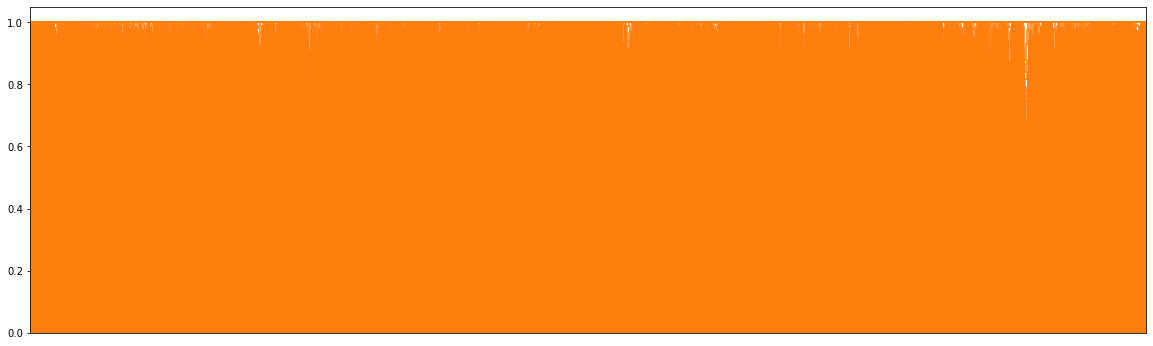

In [86]:
fig = plt.figure(figsize=(20, 6))  
fig.patch.set_facecolor('white')

d = hierarchy.dendrogram(gsXg_bin_jac_z_cluster_opt, no_labels=True, color_threshold=1.1)

In [88]:
for i in range(len(geneset_order_filtered[gsXg_bin_jac_z_cluster_opt_leaves])):
    name = geneset_order_filtered[gsXg_bin_jac_z_cluster_opt_leaves][i]
    if 'HALLMARK' in name:
        print(i)

65
66
67
73
221
693
694
717
718
861
862
1119
1386
1641
1643
1651
1780
1807
3018
3041
3147
3257
3342
3343
3786
4480
5735
10507
10831
11997
12988
13411
13528
13589
13676
13761
13936
13953
14703
14725
14839
15277
15399
15598
16167
16335
16347
16763
16764
16860


In [8]:
for i in range(1, 20):
    inds = np.where(gsXg_bin_jac_z_cluster_opt_c20.flatten() == i)[0]
    # print(inds)
    print(np.max(pdist(gsXg_bin_filtered[inds], metric='jaccard')))

NameError: name 'gsXg_bin_jac_z_cluster_opt_c20' is not defined

In [54]:
np.where(gsXg_bin_jac_z_cluster_opt_c20.flatten() == 0)[0]

array([    0,     1,     3, ..., 16905, 16906, 16908])

In [189]:
geneset_order_filtered[np.where(gsXg_bin_jac_z_cluster_opt_c20.flatten() == 19)[0]]

array(['KEGG_STEROID_BIOSYNTHESIS', 'LE_EGR2_TARGETS_DN',
       'REACTOME_EGR2_AND_SOX10_MEDIATED_INITIATION_OF_SCHWANN_CELL_MYELINATION',
       'WP_CHOLESTEROL_BIOSYNTHESIS_WITH_SKELETAL_DYSPLASIAS',
       'ZWANG_EGF_PERSISTENTLY_UP'], dtype='<U188')

In [101]:
np.where(gsXg_bin_jac_z_cluster_opt_leaves == 0)[0]

array([12673])

In [62]:
np.where(gsXg_bin_jac_z_cluster_opt_leaves == 3)

(array([16690]),)

In [63]:
gsXg_bin_jac_z_cluster_opt_leaves[[16690, 16691]]

array([   3, 6713], dtype=int32)

In [43]:
gsXg_bin_jac_z_cluster_opt_leaves[[9010, 9011]]

array([5732, 7168], dtype=int32)

In [64]:
test1 = gsXg_bin_filtered[3]
test2 = gsXg_bin_filtered[6713]

In [65]:
np.sum(test1)

13

In [66]:
np.sum(test2)

12

In [67]:
np.where((test1 == 1) & (test2 == 1))[0].shape

(2,)

array([15336,     0,   115], dtype=int32)

In [69]:
inds_in_0 = np.where(gsXg_bin_jac_z_cluster_opt_c20.flatten() == 0)[0]
for i in inds_in_0[:1]:
    where_is_i = np.where(gsXg_bin_jac_z_cluster_opt_leaves == i)[0][0]
    nearby_is = gsXg_bin_jac_z_cluster_opt_leaves[where_is_i - 1:where_is_i+2]
    pdist(gsXg_bin_filtered[nearby_is], metric='jaccard')

In [68]:
pdist([test1, test2], metric='jaccard')

array([0.91304348])

In [358]:
a = [1, 0, 0, 0, 1]
b = [1, 0, 0, 0, 1]
pdist([a, b], metric='jaccard')

array([0.])

Text(0.5, 0.9, 'Geneset x Gene, Jaccard Average Clustering')

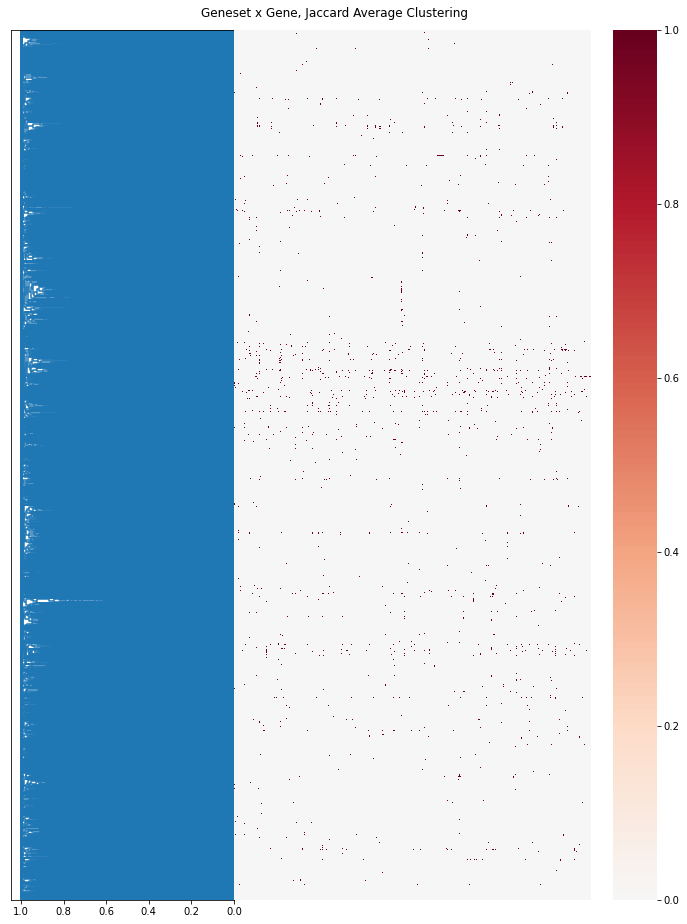

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 16), gridspec_kw={'width_ratios': [1, 2]})  
fig.patch.set_facecolor('white')
plt.subplots_adjust(wspace=0)

axes.ravel()
d = hierarchy.dendrogram(gsXg_bin_jac_z_cluster_opt, ax=axes[0], no_labels=True, color_threshold=0, orientation='left')
# axes[0].set_xticks([])

# have to flip leaves to match dendrogram
sns.heatmap(gsXg_bin_filtered[np.flip(gsXg_bin_jac_z_cluster_opt_leaves)], ax=axes[1], cmap='RdBu_r', center=0, vmax=1, vmin=0)
axes[1].set_yticks([])

axes[1].set_xticks([])

fig.suptitle('Geneset x Gene, Jaccard Average Clustering', y=0.9)

In [131]:
gs_out = []
gs_desc_out = []
for gs in geneset_order_filtered[gsXg_bin_jac_z_cluster_opt_leaves][::10]:
    gs_out.append(gs)
    gs_desc_out.append(gs2shortdesc[gs])

In [138]:
170 / 2

85.0

In [132]:
m = 1
170 * m
len(gs_desc_out)

1694

In [143]:
m = 18
for i in gs_desc_out[(85 * m):(85 * (m + 1))]:
    print(i)

Integrin-mediated cell adhesion
Malignant pleural mesothelioma
Hepatocyte growth factor receptor signaling
Angiopoietin receptor Tie2-mediated signaling
Kisspeptin/kisspeptin receptor system in the ovary
Retinoblastoma gene in cancer
MECP2 regulates neuronal receptors and channels
Non-classical role of vitamin D
The appearance of any member of the transforming growth factor-beta family of cytokines due to biosynthesis or secretion following a cellular stimulus, resulting in an increase in its intracellular or extracellular levels. Transforming growth factor-beta family members include TGF-B1, TGF-B2, and TGF-B3. [GOC:add, GOC:rv, PMID:16891311, PMID:2022183]
Any process that activates or increases the frequency, rate or extent to which it enters into the host organism, where the two organisms are in a symbiotic interaction. [GOC:pamgo_curators]
Hematopoietic cell lineage
Binding to an amine, a weakly basic organic compound that contains an amino or a substituted amino group. [GOC:jl]
C

In [143]:
# out_f = datadir + 'h_c2_c5GO_genesets.GREATv4_genes.bin.filtered.jac_ave_clusters.every1geneset.CT20230602.tsv'
# np.savetxt(out_f, np.array(gs_out).reshape(-1, 1), fmt='%s')

In [144]:
# out_arr = np.hstack((np.array(gs_out).reshape(-1, 1), np.array(gs_desc_out).reshape(-1, 1)))

In [145]:
# out_f = datadir + 'h_c2_c5GO_genesets.GREATv4_genes.bin.filtered.jac_ave_clusters.every100geneset.short_descriptions.CT20230605.tsv'
# np.savetxt(out_f, out_arr, fmt='%s', delimiter='\t')

In [275]:
spectrum_labels = ['Molecular Metabolism/Signaling', 'Lipid Metabolism', 'Cellular Processes', 'DNA Damage Response/Cell Cycle Regulation', 'Development and Differentiation', 'Cellular Signaling/Cancer', 'Cell Development', 'Cellular Signaling/Immune Response', 'Cell Response', 'Neural']

In [300]:
np.where(np.isin(geneset_order_filtered[gsXg_bin_jac_z_cluster_opt_leaves], sig_gs))

(array([ 1149,  3983,  4781,  4782,  4783,  6359,  6360,  6361,  6362,
         6382,  6417,  6418,  6419,  6663,  6664,  6665,  6666,  6670,
         6674,  6675,  6688,  6689,  6693,  6704,  6705,  6706,  6707,
         6708,  6709,  6711,  6717,  6721,  6722,  6723,  6727,  6728,
         6730,  6736,  6737,  6738,  6739,  6741,  6749,  6770,  6840,
         6944,  7001,  7003,  7076,  7105,  7107,  7109,  7116,  7117,
         7121,  7122,  7123,  7124,  7130,  7131,  7132,  7133,  7148,
         7151,  7152,  7153,  7154,  7155,  7156,  7162,  7163,  7164,
         7168,  7169,  7190,  7298,  7299,  7300,  7303,  7304,  7305,
         7306,  7307,  7342,  7554,  7562,  7613,  7615,  7656,  7688,
         7704,  7705,  7943,  9394,  9422,  9423,  9424,  9435,  9450,
         9451,  9452,  9453,  9454,  9455,  9456,  9457,  9480,  9502,
         9503,  9504,  9505,  9506,  9507,  9509,  9510,  9511, 10180,
        10182, 10185, 10186, 10187, 10188, 10189, 10190, 10191, 10192,
      

In [317]:
np.where(geneset_order_filtered[gsXg_bin_jac_z_cluster_opt_leaves] == 'GOBP_NEUROEPITHELIAL_CELL_DIFFERENTIATION')

(array([6736]),)

In [301]:
sig_gs

['GOMF_DNA_BINDING_TRANSCRIPTION_FACTOR_ACTIVITY',
 'GOMF_SEQUENCE_SPECIFIC_DNA_BINDING',
 'GOMF_RNA_POLYMERASE_II_TRANSCRIPTION_REGULATORY_REGION_SEQUENCE_SPECIFIC_DNA_BINDING',
 'GOMF_TRANSCRIPTION_REGULATOR_ACTIVITY',
 'GOCC_CHROMATIN',
 'GOCC_CHROMOSOME',
 'BENPORATH_EED_TARGETS',
 'BENPORATH_ES_WITH_H3K27ME3',
 'BENPORATH_PRC2_TARGETS',
 'MEISSNER_BRAIN_HCP_WITH_H3K27ME3',
 'BENPORATH_SUZ12_TARGETS',
 'GOBP_PATTERN_SPECIFICATION_PROCESS',
 'GOBP_POSITIVE_REGULATION_OF_TRANSCRIPTION_BY_RNA_POLYMERASE_II',
 'GOMF_DNA_BINDING_TRANSCRIPTION_ACTIVATOR_ACTIVITY',
 'GOBP_POSITIVE_REGULATION_OF_RNA_METABOLIC_PROCESS',
 'GOBP_POSITIVE_REGULATION_OF_MACROMOLECULE_BIOSYNTHETIC_PROCESS',
 'GOBP_CENTRAL_NERVOUS_SYSTEM_DEVELOPMENT',
 'GOBP_HEAD_DEVELOPMENT',
 'GOBP_CELL_FATE_COMMITMENT',
 'GOBP_GENERATION_OF_NEURONS',
 'GOBP_EMBRYONIC_ORGAN_MORPHOGENESIS',
 'GOBP_ANIMAL_ORGAN_MORPHOGENESIS',
 'GOBP_FOREBRAIN_DEVELOPMENT',
 'MIKKELSEN_MEF_HCP_WITH_H3K27ME3',
 'GOBP_EMBRYONIC_MORPHOGENESIS',
 'GO

In [322]:
geneset_filtered_cluster_order = geneset_order_filtered[gsXg_bin_jac_z_cluster_opt_leaves]

In [340]:
window_size = 100
sig_gs_inds = np.where(np.isin(geneset_filtered_cluster_order, sig_gs))[0]
spectrum_sums = []
for i in range(len(geneset_filtered_cluster_order)):
    test_inds = np.arange(i - int(window_size / 2), i + int(window_size / 2))
    count = np.count_nonzero(np.isin(test_inds, sig_gs_inds))
    spectrum_sums.append(count)

In [342]:
len(sig_gs_inds)

161

[Text(0.05, 0, 'Molecular Metabolism/Signaling'),
 Text(0.15000000000000002, 0, 'Lipid Metabolism'),
 Text(0.25, 0, 'Cellular Processes'),
 Text(0.35, 0, 'DNA Damage Response/Cell Cycle Regulation'),
 Text(0.45, 0, 'Development and Differentiation'),
 Text(0.55, 0, 'Cellular Signaling/Cancer'),
 Text(0.65, 0, 'Cell Development'),
 Text(0.75, 0, 'Cellular Signaling/Immune Response'),
 Text(0.8500000000000001, 0, 'Cell Response'),
 Text(0.9500000000000001, 0, 'Neural')]

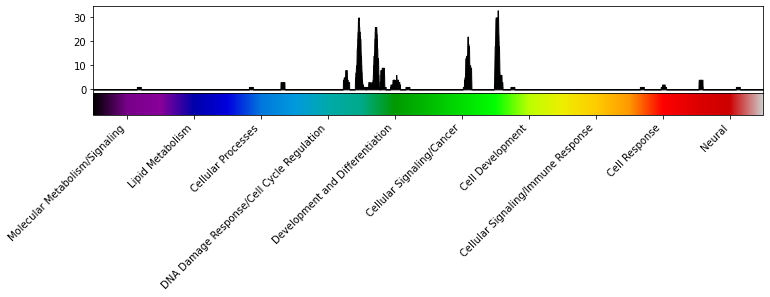

In [343]:

    
    


fig, axes = plt.subplots(2, 1, figsize=(12, 2), gridspec_kw={'height_ratios': [4, 1]})  
fig.patch.set_facecolor('white')
plt.subplots_adjust(hspace=0)

axes.ravel()

axes[0].fill_between(range(len(spectrum_sums)), spectrum_sums, color='k')
axes[0].set_xticks([])
axes[0].set_xlim([0, len(spectrum_sums)])

colors = cm.get_cmap('nipy_spectral', len(geneset_order_filtered))
matplotlib.colorbar.ColorbarBase(axes[1], cmap=colors, orientation='horizontal').set_ticks(np.arange(len(spectrum_labels)) / len(spectrum_labels) + 0.05)
axes[1].set_xticklabels(spectrum_labels, rotation=45, ha='right')

# fig.suptitle('Geneset x Gene, Jaccard Average Clustering', y=0.9)

In [10]:
# gsXg_bin_jac_z_cluster_opt_c100 = hierarchy.cut_tree(gsXg_bin_jac_z_cluster_opt, n_clusters=100)
# gsXg_bin_jac_z_cluster_opt_c200 = hierarchy.cut_tree(gsXg_bin_jac_z_cluster_opt, n_clusters=200)
# gsXg_bin_jac_z_cluster_c100 = hierarchy.cut_tree(gsXg_bin_jac_z_cluster, n_clusters=100)
# gsXg_bin_jac_z_cluster_opt_c10 = hierarchy.cut_tree(gsXg_bin_jac_z_cluster_opt, n_clusters=10)
gsXg_bin_jac_z_cluster_opt_c20 = hierarchy.cut_tree(gsXg_bin_jac_z_cluster_opt, n_clusters=20)

In [7]:
np.bincount(gsXg_bin_jac_z_cluster_opt_c20.flatten())

array([16670,    10,    22,    38,    51,    38,    21,     6,     9,
           4,     9,    11,     2,     4,     5,     9,     4,    13,
           6,     5])

In [9]:
# getting geneset clusters in order, representative chosen at random
cluster_info = []
rep_inds = []
for i in range(100):
    # find genesets in each cluster
    inds = np.where(gsXg_bin_jac_z_cluster_opt_c100==i)[0]
    num_genes_for_inds = np.sum(gsXg_bin_filtered[inds], axis=1)
    ave_num_genes = str(np.round(np.mean(num_genes_for_inds), 1))
    rep = np.random.choice(geneset_order_filtered[inds])
    cluster_info.append([rep, len(inds), ave_num_genes])
    
    rep_ind = np.where(geneset_order_filtered[gsXg_bin_jac_z_cluster_opt_leaves] == rep)[0][0]
    rep_inds.append(rep_ind)
    
rep_inds = np.array(rep_inds)
rep_inds_order = np.argsort(rep_inds)
cluster_info = np.array(cluster_info)
print('Representative Geneset\tNumber of Genesets in Cluster\tAverage Number of Genes in Clustered Genesets')
print()
for row in cluster_info[rep_inds_order]:
    print('%s\t%s\t%s' %(row[0], row[1], row[2]))

Representative Geneset	Number of Genesets in Cluster	Average Number of Genes in Clustered Genesets

GOCC_MON1_CCZ1_COMPLEX	1	4.0
GOMF_PHEROMONE_RECEPTOR_ACTIVITY	2	4.5
GOBP_N_ACYLETHANOLAMINE_METABOLIC_PROCESS	7	12.1
REACTOME_HDMS_DEMETHYLATE_HISTONES	58	20.3
GOBP_NEGATIVE_REGULATION_OF_CELL_VOLUME	10	10.8
WALLACE_PROSTATE_CANCER_DN	21	15.3
FIGUEROA_AML_METHYLATION_CLUSTER_1_DN	5	20.6
GARGALOVIC_RESPONSE_TO_OXIDIZED_PHOSPHOLIPIDS_LIGHTYELLOW_UP	13	18.1
NIKOLSKY_BREAST_CANCER_20Q12_Q13_AMPLICON	7	46.0
GOBP_DETECTION_OF_VIRUS	4	9.0
GOBP_GALACTOSE_CATABOLIC_PROCESS	327	37.6
BARRIER_COLON_CANCER_RECURRENCE_DN	63	19.9
ASTIER_INTEGRIN_SIGNALING	4	33.0
BARRIER_COLON_CANCER_RECURRENCE_UP	11	14.7
GOBP_POSITIVE_REGULATION_OF_PINOCYTOSIS	38	10.7
GOCC_WASH_COMPLEX	8	29.6
MIKKELSEN_ES_LCP_WITH_H3K4ME3	9	81.1
GOMF_5_3_DNA_EXONUCLEASE_ACTIVITY	18	8.6
BIOCARTA_IGF1MTOR_PATHWAY	463	74.6
GOMF_INTRONIC_TRANSCRIPTION_REGULATORY_REGION_SEQUENCE_SPECIFIC_DNA_BINDING	10	14.4
BOYLAN_MULTIPLE_MYELOMA_PCA1_DN	1

In [8]:
# chose representative based on term enrichment
bad_terms = ['THE', 'OF', 'VS', 'UP', 'DN', 'ACTIVITY', 'TO', 'IN', 
             'N', 'PROTEIN', 'TARGETS', 'TARGET', 'AND', 'BINDING', 
             'PROCESS', 'OK']

gs_filtered_terms_cut = []
for gs in geneset_order_filtered:
    gs_filtered_terms_cut.extend(gs.split('_'))
gs_filtered_terms_cut = np.array(gs_filtered_terms_cut)

gs_filtered_terms, gs_filtered_term_counts = np.unique(gs_filtered_terms_cut[~np.isin(gs_filtered_terms_cut, bad_terms)], return_counts=True)
gs_filtered_term_exp = gs_filtered_term_counts / np.sum(gs_filtered_term_counts)

In [10]:
# getting geneset clusters in order, representative chosen by enrichment

cluster_info = []
rep_inds = []
for i in range(20):
    # find genesets in each cluster
    inds = np.where(gsXg_bin_jac_z_cluster_opt_c20==i)[0]
    num_genes_for_inds = np.sum(gsXg_bin_filtered[inds], axis=1)
    ave_num_genes = str(np.round(np.mean(num_genes_for_inds), 1))
    
    # get geneset names
    clustered_geneset_names = geneset_order_filtered[inds]
    
    # get terms in geneset names
    cluster_terms_full = []
    for name in clustered_geneset_names:
        cluster_terms_full.extend(name.split('_')[1:])
    cluster_terms_full = np.array(cluster_terms_full)
    cluster_terms_full = cluster_terms_full[~np.isin(cluster_terms_full, bad_terms)]

    # calculate observed over expected
    cluster_terms, cluster_term_counts = np.unique(cluster_terms_full, return_counts=True)
    cluster_term_obs = cluster_term_counts / np.sum(cluster_term_counts)
    cluster_term_exp = gs_filtered_term_exp[np.isin(gs_filtered_terms, cluster_terms)]
    cluster_term_ooe = np.log2(cluster_term_obs / cluster_term_exp)
    # eliminate terms that just show up once
    cluster_term_ooe = np.where(cluster_term_counts > 1, cluster_term_ooe, 0)
    top_ooe_term = cluster_terms[np.argsort(-cluster_term_ooe)[:3]]
    top_count_term = cluster_terms[np.argsort(-cluster_term_counts)[:3]]
    
    # find the average enrichment of all terms in each geneset
    cluster_geneset_aveenrich = []
    for name in clustered_geneset_names:
        name_terms = np.array(name.split('_')[1:])
        name_terms = name_terms[~np.isin(name_terms, bad_terms)]
        cluster_geneset_aveenrich.append(np.mean(cluster_term_ooe[np.isin(cluster_terms, name_terms)]))
    cluster_geneset_aveenrich = np.array(cluster_geneset_aveenrich)
    
    # get representative geneset
    rep = clustered_geneset_names[np.argsort(-cluster_geneset_aveenrich)[0]]

    cluster_info.append([rep, len(inds), ave_num_genes, top_ooe_term, top_count_term])    
    rep_ind = np.where(geneset_order_filtered[gsXg_bin_jac_z_cluster_opt_leaves] == rep)[0][0]
    rep_inds.append(rep_ind)
    
rep_inds = np.array(rep_inds)
rep_inds_order = np.argsort(rep_inds)
cluster_info = np.array(cluster_info)
# print('Ind\tRepresentative Geneset\tNumber of Genesets in Cluster\tAverage Number of Genes in Clustered Genesets')
print('Ind\tRepresentative Terms\tNumber of Genesets in Cluster\tAverage Number of Genes in Clustered Genesets')
print()
for i in range(20):
    row = cluster_info[rep_inds_order][i]
    print('%s\t%s\t%s\t%s' %(i, row[3], row[1], row[2]))

Ind	Representative Terms	Number of Genesets in Cluster	Average Number of Genes in Clustered Genesets

0	['NEOPLASTIC' 'TRANSFORMATION' 'KRAS']	22	413.2
1	['EGR2' 'BIOSYNTHESIS' 'CELL']	5	37.0
2	['ACYLTRANSFERASE' 'O' 'METABOLISM']	9	44.3
3	['BLEBBISHIELD' 'CDH1' '1']	9	176.9
4	['LPS' 'NFKB' 'IL2']	38	178.8
5	['MC' 'SATB1' 'DOXORUBICIN']	38	518.9
6	['ARTERIAL' 'BLOOD' 'BODY']	4	7.8
7	['CORONARY' 'VEGF' 'SPROUTING']	51	24.6
8	['PAX' 'HR' 'CMV']	9	114.9
9	['TNF' 'SIGNALING' 'RESPONSE']	4	51.8
10	['COPII' 'DEACETYLATION' 'ORGANOPHOSPHATE']	16670	75.8
11	['ENDOCRINE' 'PANCREATIC' 'PROGENITOR']	6	19.2
12	['EXOCRINE' 'PANCREATIC' 'CELLS']	4	9.2
13	['HR' 'CMV' 'INTERFERON']	21	42.5
14	['GROWTH' 'FACTOR' 'CELLULAR']	11	13.2
15	['MUCUS' 'PURINERGIC' 'NUCLEOTIDE']	13	14.6
16	['TRETINOIN' 'RESPONSE' 'CANCER']	5	11.6
17	['PROLIFERATOR' 'PEROXISOME' 'RIGHT']	10	15.0
18	['ESTRADIOL' 'AKT1' 'ESR1']	6	165.3
19	['ANEUPLOIDY' 'EGF' 'PERSISTENTLY']	2	48.5


/tmp/ipykernel_36660/2036165135.py:48: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  cluster_info = np.array(cluster_info)


In [347]:
i=rep_inds_order[29]
inds = np.where(gsXg_bin_jac_z_cluster_opt_c10==i)[0]
geneset_order_filtered[inds]

IndexError: index 29 is out of bounds for axis 0 with size 10

Scale-based region sampling

In [117]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
ss_f = datadir + 'regions_25kb_CT20230427.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.npz'

ss_coords = np.load(ss_f)['coordinates']
ss_ranks = np.load(ss_f)['percentiles']
ss_factors = np.load(ss_f, allow_pickle=True)['factors']

In [159]:
geneset_tracker = []

for ind in [6000, 1020, 2178, 21092, 17201]:

    query_coords = ss_coords[ind][0] + ':' + ss_coords[ind][1] + '-' + ss_coords[ind][2]
    scale = 25

    response = production_post_request(query_coords, scale)
    query_full_data = json.loads(response.text)

    prod_ranks = []
    for i in range(len(query_full_data)):
        prod_ranks.append(query_full_data[i][0]['prod_rank'])

    dl = np.argmax(prod_ranks) + 1

    query_sim_region_inds = []
    query_sim_region_coords = []
    for i in range(1, len(query_full_data[0])):
        coord = re.split('[:-]', query_full_data[dl - 1][i]['coordinates'])
        query_sim_region_coords.append(coord)
        query_sim_region_inds.append(query_full_data[dl - 1][i]['region_ind'])

    query_tested_gs, query_tested_gs_pval = query_sim_hypergeom(query_sim_region_inds, N=100)

    # c = 0
    sort_order = np.argsort(query_tested_gs_pval)

    for i, j in zip(query_tested_gs[sort_order], query_tested_gs_pval[sort_order]):
        if (j * len(geneset_order)) < 0.05:
    #         print(i + '\t' + str(j))
    #         c += 1
            geneset_tracker.append(i)


In [160]:
np.unique(geneset_tracker).shape

(219,)

For all genes in each geneset, find corresponding region ranks

In [63]:
# datadir = '/home/ctrader/region_similarity/data/rank_based/'
# ss_f = datadir + 'regions_25kb_CT20230427.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.npz'

# # ss_coords = np.load(ss_f)['coordinates']
# ss_ranks = np.load(ss_f)['percentiles']
# # ss_factors = np.load(ss_f, allow_pickle=True)['factors']

In [31]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
in_f = datadir + 'h_c2_c5GO_genesets.GREATv4_genes.bin.CT20230601.npz'
gene_order = np.load(in_f)['gene_order']
geneset_order = np.load(in_f)['geneset_order']

In [24]:
# create a search space region x gene matrix
datadir = '/home/ctrader/region_similarity/data/rank_based/'
mapped_f = datadir + 'regions_25kb_CT20230601.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.sorted.GREATv4_genes_extended_domain_1000kb_mapped.bed'

f = open(mapped_f)
lines = f.readlines()
f.close()

# binary matrix for genes located in each search space region
search_space_gene_bin = np.zeros((len(lines), len(gene_order)), dtype=int)

# for each search space region, populate binary matrix
for i in range(len(lines)):
    line = lines[i]
    line = re.split('[\t|;]', line.strip())
    mapped_genes = line[4:]
    
    gene_inds = np.where(np.isin(gene_order, mapped_genes))[0]
    
    search_space_gene_bin[i, gene_inds] = 1

In [32]:
geneset_order.shape

(16948,)

In [101]:
# for each geneset, get corresponding genes. 
# for those genes, find regions they map too
# for those regions, get ranks and average
# geneset -> 34 ranks

for gs in geneset_order[:1]:
    # get genes for geneset
    gs_genes = geneset2genes[gs]
    # find the indices for genes
    gs_gene_inds = np.where(np.isin(gene_order, gs_genes))[0]
    # find the regions that are hit by these genes
    ss_regions_with_gs_genes = np.unique(np.where(search_space_gene_bin[:, gs_gene_inds])[0])
    # get ranks for all regions hit by geneset genes
    gs_region_ranks = ss_ranks[ss_regions_with_gs_genes]
    # average
    gs_mean_region_ranks = np.mean(gs_region_ranks, axis=0)

In [92]:
ss_regions_with_gs_genes.shape

(130,)

In [90]:
search_space_gene_bin.shape

(32749, 18774)

In [102]:
gs_mean_region_ranks

array([0.64015305, 0.63480157, 0.6429847 , 0.62248087, 0.6370933 ,
       0.6668135 , 0.6057311 , 0.5596428 , 0.7200908 , 0.6904398 ,
       0.62816805, 0.70134234, 0.6608441 , 0.65883833, 0.66708225,
       0.6189651 , 0.46412042, 0.50086135, 0.61002725, 0.6445449 ,
       0.32214728, 0.50985354, 0.53933775, 0.6177661 , 0.6742724 ,
       0.71724945, 0.6585731 , 0.21637684, 0.14724712, 0.2796176 ,
       0.41949958, 0.2905322 , 0.2855711 , 0.1703448 ], dtype=float32)

Sample regions, create geneset x query region matrix with -log10 pvalues

In [205]:
order = 11

datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert/'
in_f = datadir + 'hilbert_regions_order_{}.search_space_top_1000_no_overlap.mapped_extended_domain_GREATv4_gene_c5GOBP_genesets.bin.CT20230608.npy'.format(order)

search_space_geneset_bin = np.load(in_f)

In [206]:
search_space_geneset_bin.shape

(33975, 7751)

In [207]:
# build dictionary of genesets mapping to a list of genes
geneset2genes = {}
for gs_f in [c5gobp_f]:  # hallmark_f, c2_f, c5go_f
    f = open(gs_f)
    for line in f.readlines():
        line = line.strip().split('\t')
        gs = line[0]
        genes = line[2:]
        geneset2genes[gs] = genes
    f.close()
geneset_order = np.unique(list(geneset2genes.keys()))

In [208]:
geneset_order

array(['GOBP_10_FORMYLTETRAHYDROFOLATE_METABOLIC_PROCESS',
       'GOBP_2FE_2S_CLUSTER_ASSEMBLY',
       'GOBP_2_OXOGLUTARATE_METABOLIC_PROCESS', ...,
       'GOBP_ZYGOTIC_DETERMINATION_OF_ANTERIOR_POSTERIOR_AXIS_EMBRYO',
       'GOBP_ZYMOGEN_ACTIVATION', 'GOBP_ZYMOGEN_INHIBITION'],
      dtype='<U148')

In [209]:
ss_f = datadir + 'hilbert_regions_order_{}_CT20230606.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.npz'.format(order)

ss_coords = np.load(ss_f)['coordinates']

In [210]:
num_regions = search_space_geneset_bin.shape[0]
gs_region_counts = np.sum(search_space_geneset_bin, axis=0)

exp = gs_region_counts / num_regions
exp = np.where(exp == 0, 0.00001, exp)  # pseudocount

num_regions_to_sample = np.min([num_regions_to_sample, num_regions])

In [211]:
search_space_geneset_bin.shape

(33975, 7751)

In [212]:
np.max(gs_region_counts)

8229

In [213]:
def production_post_request(coords, order, num_sim_regions):
    prod_url = 'https://explore.altius.org:5001/narration'
    post_body = {
        'location': coords,
        'factors': '[' + ','.join(np.arange(34).astype(str)) + ']',
        'roiURL': 'False',
        'scale': order,
        'queryFactorThresh': '0.5',
        'numSimilarRegions': str(num_sim_regions),
        'regionMethod': 'hilbert'
    }
    response = requests.post(prod_url, json=post_body)
    return response

def query_sim_hypergeom(region_inds, N, M, n, geneset_order, search_space_geneset_bin):
    k = np.sum(search_space_geneset_bin[region_inds], axis=0)
    inds_to_test = np.where(k)[0]

    test = hypergeom.sf(k[inds_to_test], M, n[inds_to_test], N)
    tested_genesets = geneset_order[inds_to_test]
    test = test * len(geneset_order)  # bonferroni correction
    test = np.where(test > 1, 1, test)
    return tested_genesets, inds_to_test, test

def query_sim_enrichment(region_inds, search_space_geneset_bin, exp):
    num_regions_sampled = len(region_inds)
    # how many sampled regions does each geneset fall in
    gs_sampled_region_count = np.sum(search_space_geneset_bin[region_inds], axis=0)
    obs = gs_sampled_region_count / num_regions_sampled
    # observed / expected enrichment
    log2ooe = np.log2(obs / exp)
    
    return log2ooe

In [214]:
num_regions_to_sample = 50

In [724]:
# geneset x number of sampled regions
geneset_sampled_region_log2ooe = np.zeros((len(geneset_order), num_regions_to_sample), dtype=float)
# regions to sample
sampled_region_inds = np.random.choice(num_regions, num_regions_to_sample, replace=False)
for sample_ind, sample_i in zip(sampled_region_inds, range(num_regions_to_sample)):
    c = ss_coords[sample_ind]
    query_coords = c[0] + ':' + c[1] + '-' + c[2]

    # get similar regions
    response = production_post_request(query_coords, order, num_sim_regions)
    query_full_data = json.loads(response.text)

    # find best detail level
    prod_ranks = []
    for i in range(len(query_full_data)):
        prod_ranks.append(query_full_data[i][0]['prod_rank'])
    dl = np.argmax(prod_ranks) + 1

    query_sim_region_inds = []
    query_sim_region_inds.append(sample_ind)
    for i in range(1, len(query_full_data[0])):
        query_sim_region_inds.append(query_full_data[dl - 1][i]['region_ind'])

    # test for geneset enrichment
    log2ooe = query_sim_enrichment(query_sim_region_inds, search_space_geneset_bin, exp)

    geneset_sampled_region_log2ooe[:, sample_i] = log2ooe

In [260]:
all_orders_log2ooe.shape

(7751, 7000)

In [300]:
datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert/'
start_o = 4
end_o = 10
sample_size = 1000

all_orders_log2ooe = np.zeros((len(geneset_order), len(np.arange(start_o, end_o + 1)) * sample_size))
for order in np.arange(start_o, end_o+1):
    order_f_format = 'hilbert_regions_order_{}_search_space_c5GOBP_geneset_sampling.\d+_regions.100_sim_regions.CT20230608.npz'.format(order)
    for filename in os.listdir(datadir):
        if re.match(order_f_format, filename):
            order_f = filename

    order_log2ooe = np.load(datadir + order_f)['geneset_sampled_region_log2ooe']
    all_orders_log2ooe[
        :,
        ((order - start_o) * sample_size):((order + 1 - start_o) * sample_size)
    ] = order_log2ooe[:, :sample_size]
    
# any under enrichment set to 0
all_orders_log2ooe = np.where(all_orders_log2ooe < 0, 0, all_orders_log2ooe)

# remove genesets that are never enriched
inds_to_keep = np.where(np.count_nonzero(all_orders_log2ooe, axis=1) > 0)[0]
all_orders_log2ooe_sampfiltered = all_orders_log2ooe[inds_to_keep]
geneset_order_sampfiltered = geneset_order[inds_to_keep]

In [304]:
# out_f = datadir + 'hilbert_regions_orders_4t10_search_space_c5GOBP_geneset_sampling.1000_regions_per_order.100_sim_regions.filtered.CT20230609.npz'
# np.savez(out_f, log2ooe=all_orders_log2ooe_sampfiltered, geneset_order=geneset_order_sampfiltered)

Per Scale

In [726]:
# Order 4
distance_4 = pdist(all_orders_log2ooe_sampfiltered[:, :1000], metric='euclidean')
Z_4 = hierarchy.complete(distance_4)
Z_opt_4 = hierarchy.optimal_leaf_ordering(Z_4, distance_4)
opt_leaves_4 = hierarchy.leaves_list(Z_opt_4)

Text(0.5, 1.0, 'Order 4, Euclidean, Complete Linkage, Optimally Ordered, Cut Height=65')

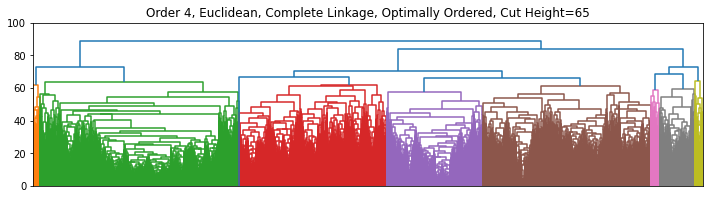

In [834]:
fig = plt.figure(figsize=(12, 3))  
fig.patch.set_facecolor('white')

cut_height = 65
d4 = hierarchy.dendrogram(Z_opt_4, no_labels=True, color_threshold=cut_height)
plt.ylim([0, 100])

plt.title('Order 4, Euclidean, Complete Linkage, Optimally Ordered, Cut Height=%s' %cut_height)

In [740]:
# Order 5
distance_5 = pdist(all_orders_log2ooe_sampfiltered[:, 1000:2000], metric='euclidean')
Z_5 = hierarchy.complete(distance_5)
Z_opt_5 = hierarchy.optimal_leaf_ordering(Z_5, distance_5)
opt_leaves_5 = hierarchy.leaves_list(Z_opt_5)

Text(0.5, 1.0, 'Order 5, Euclidean, Complete Linkage, Optimally Ordered, Cut Height=0')

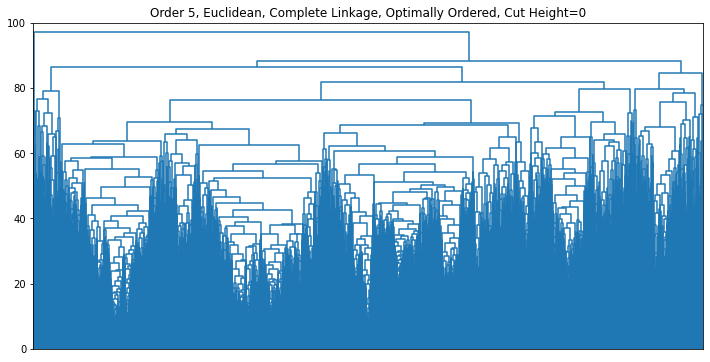

In [767]:
fig = plt.figure(figsize=(12, 6))  
fig.patch.set_facecolor('white')

cut_height = 0
d4 = hierarchy.dendrogram(Z_opt_5, no_labels=True, color_threshold=cut_height)
plt.ylim([0, 100])

plt.title('Order 5, Euclidean, Complete Linkage, Optimally Ordered, Cut Height=%s' %cut_height)

In [730]:
# Order 6
distance_6 = pdist(all_orders_log2ooe_sampfiltered[:, 2000:3000], metric='euclidean')
Z_6 = hierarchy.complete(distance_6)
Z_opt_6 = hierarchy.optimal_leaf_ordering(Z_6, distance_6)
opt_leaves_6 = hierarchy.leaves_list(Z_opt_6)

Text(0.5, 1.0, 'Order 6, Euclidean, Complete Linkage, Optimally Ordered, Cut Height=0')

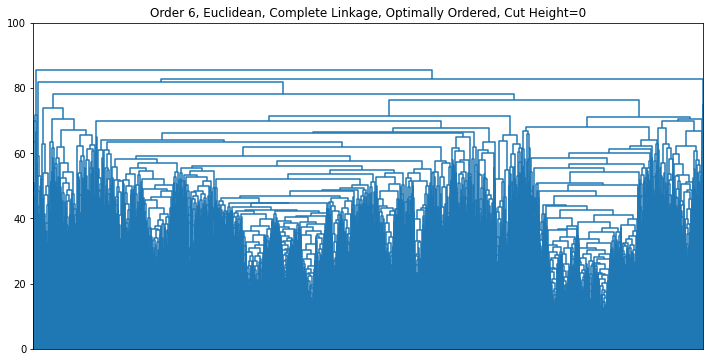

In [768]:
fig = plt.figure(figsize=(12, 6))  
fig.patch.set_facecolor('white')

cut_height = 0
d4 = hierarchy.dendrogram(Z_opt_6, no_labels=True, color_threshold=cut_height)
plt.ylim([0, 100])

plt.title('Order 6, Euclidean, Complete Linkage, Optimally Ordered, Cut Height=%s' %cut_height)

In [732]:
# Order 7
distance_7 = pdist(all_orders_log2ooe_sampfiltered[:, 3000:4000], metric='euclidean')
Z_7 = hierarchy.complete(distance_7)
Z_opt_7 = hierarchy.optimal_leaf_ordering(Z_7, distance_7)
opt_leaves_7 = hierarchy.leaves_list(Z_opt_7)

Text(0.5, 1.0, 'Order 7, Euclidean, Complete Linkage, Optimally Ordered, Cut Height=0')

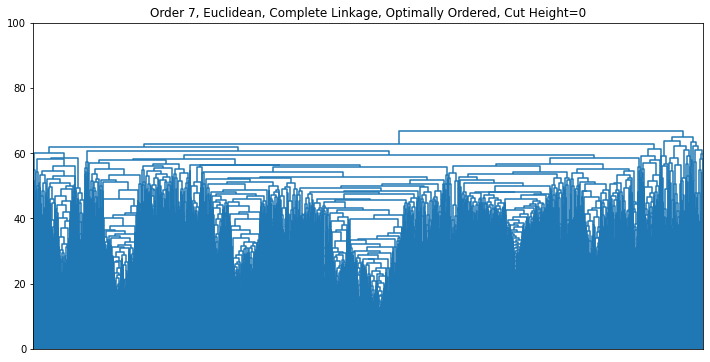

In [769]:
fig = plt.figure(figsize=(12, 6))  
fig.patch.set_facecolor('white')

cut_height = 0
d4 = hierarchy.dendrogram(Z_opt_7, no_labels=True, color_threshold=cut_height)
plt.ylim([0, 100])

plt.title('Order 7, Euclidean, Complete Linkage, Optimally Ordered, Cut Height=%s' %cut_height)

In [734]:
# Order 8
distance_8 = pdist(all_orders_log2ooe_sampfiltered[:, 4000:5000], metric='euclidean')
Z_8 = hierarchy.complete(distance_8)
Z_opt_8 = hierarchy.optimal_leaf_ordering(Z_8, distance_8)
opt_leaves_8 = hierarchy.leaves_list(Z_opt_8)

Text(0.5, 1.0, 'Order 8, Euclidean, Complete Linkage, Optimally Ordered, Cut Height=0')

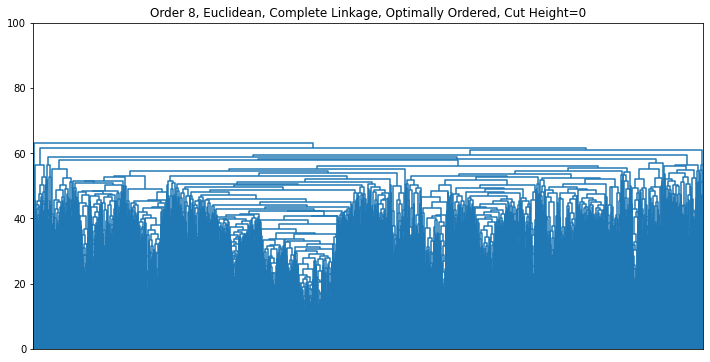

In [770]:
fig = plt.figure(figsize=(12, 6))  
fig.patch.set_facecolor('white')

cut_height = 0
d4 = hierarchy.dendrogram(Z_opt_8, no_labels=True, color_threshold=cut_height)
plt.ylim([0, 100])

plt.title('Order 8, Euclidean, Complete Linkage, Optimally Ordered, Cut Height=%s' %cut_height)

In [736]:
# Order 9
distance_9 = pdist(all_orders_log2ooe_sampfiltered[:, 5000:6000], metric='euclidean')
Z_9 = hierarchy.complete(distance_9)
Z_opt_9 = hierarchy.optimal_leaf_ordering(Z_9, distance_9)
opt_leaves_9 = hierarchy.leaves_list(Z_opt_9)

Text(0.5, 1.0, 'Order 9, Euclidean, Complete Linkage, Optimally Ordered, Cut Height=0')

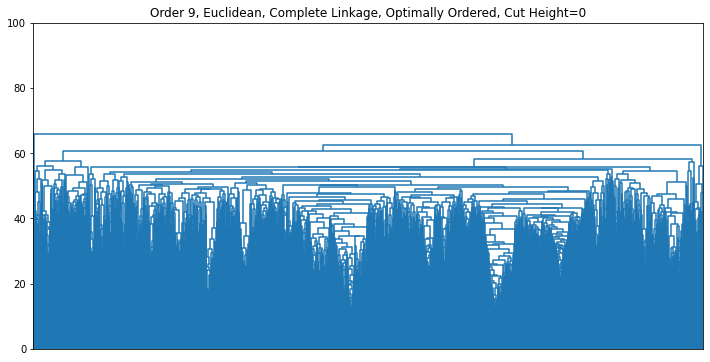

In [771]:
fig = plt.figure(figsize=(12, 6))  
fig.patch.set_facecolor('white')

cut_height = 0
d4 = hierarchy.dendrogram(Z_opt_9, no_labels=True, color_threshold=cut_height)
plt.ylim([0, 100])

plt.title('Order 9, Euclidean, Complete Linkage, Optimally Ordered, Cut Height=%s' %cut_height)

In [738]:
# Order 10
distance_10 = pdist(all_orders_log2ooe_sampfiltered[:, 6000:7000], metric='euclidean')
Z_10 = hierarchy.complete(distance_10)
Z_opt_10 = hierarchy.optimal_leaf_ordering(Z_10, distance_10)
opt_leaves_10 = hierarchy.leaves_list(Z_opt_10)

Text(0.5, 1.0, 'Order 10, Euclidean, Complete Linkage, Optimally Ordered, Cut Height=0')

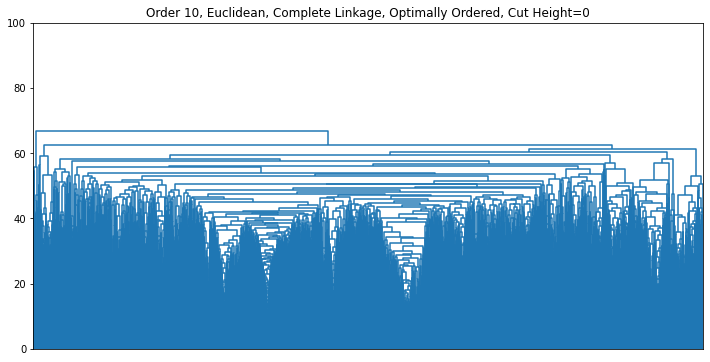

In [772]:
fig = plt.figure(figsize=(12, 6))  
fig.patch.set_facecolor('white')

cut_height = 0
d4 = hierarchy.dendrogram(Z_opt_10, no_labels=True, color_threshold=cut_height)
plt.ylim([0, 100])

plt.title('Order 10, Euclidean, Complete Linkage, Optimally Ordered, Cut Height=%s' %cut_height)

In [802]:
all_order_sparsity = []
all_order_geneset_participation = []
for i in range(7):
    order_log2ooe = all_orders_log2ooe_sampfiltered[:, (1000 * i):(1000 * (i + 1))]
    
    order_sparsity = 1 - (np.count_nonzero(order_log2ooe) / (order_log2ooe.shape[0] * order_log2ooe.shape[1]))
    all_order_sparsity.append(order_sparsity)
    
    gs_participating = len(np.where(np.count_nonzero(order_log2ooe, axis=1) > 0)[0])
    all_order_geneset_participation.append(gs_participating)

Text(0.5, 1.0, 'Sparsity of sampled data at different orders')

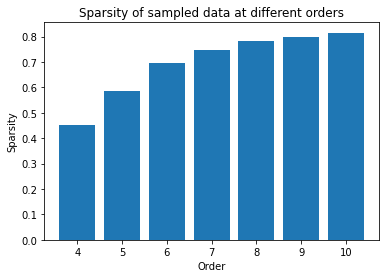

In [765]:
fig = plt.figure() # figsize=(12, 6)
fig.patch.set_facecolor('white')

plt.bar(range(len(all_order_sparsity)), all_order_sparsity)

plt.xticks(np.arange(7), np.arange(7)+4)

plt.xlabel('Order')
plt.ylabel('Sparsity')


plt.title('Sparsity of sampled data at different orders')

Text(0.5, 1.0, 'Geneset participation at each order')

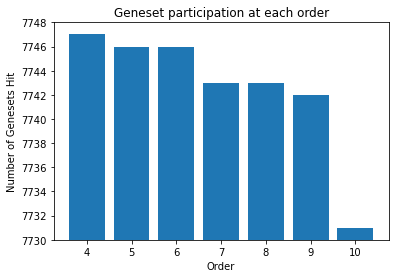

In [809]:
fig = plt.figure() # figsize=(12, 6)
fig.patch.set_facecolor('white')

plt.bar(range(len(all_order_geneset_participation)), all_order_geneset_participation)

plt.xticks(np.arange(7), np.arange(7)+4)

plt.xlabel('Order')
plt.ylabel('Number of Genesets Hit')
plt.ylim([7730, 7748])

plt.title('Geneset participation at each order')

In [812]:
euc4_gs_order = geneset_order_sampfiltered[opt_leaves_4]

Text(0.5, 1.04, 'Order 4, Euclidean, Complete Linkage, Optimally Ordered, ALL Themes')

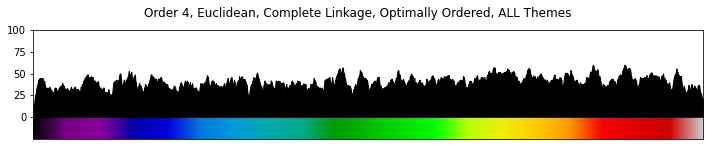

In [857]:
# order 4 only
window_size = 100
term_gs_inds = np.array([])


title = 'Immune Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'IMMUN') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'INTERLEUKIN') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'INTERFERON') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'B_CELL') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'T_CELL') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'LYMPHOCYTE') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'NEUTROPHIL') > -1)[0]
)

title = 'Cardiac Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'CARD') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'HEART') > -1)[0]
)

title = 'Neural Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'BRAIN') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'NEUR') > -1)[0]
)

title = 'Development/Differentiation Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'DEVELOPMENT') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'DIFFERENTIATION') > -1)[0]
)

title = 'Cell Cycle Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'CELL_CYCLE') > -1)[0]
)

# title = 'Viral Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(euc4_gs_order, 'VIRUS') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(euc4_gs_order, 'VIRAL') > -1)[0]
# )

title = 'Lipid Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'LIPID') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'FATTY_ACID') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'STEROID') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'HORMONE') > -1)[0]
)

title = 'Ion Transport Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(
        (np.char.find(euc4_gs_order, 'TRANSPORT') > -1) & 
        (np.char.find(euc4_gs_order, '_ION') > -1)
    )[0]
)

title = 'Muscle Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'MUSCLE') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'MUSCUL') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'MYO') > -1)[0]
)

title = 'DNA Repair Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(
        (np.char.find(euc4_gs_order, 'DNA') > -1) & 
        (np.char.find(euc4_gs_order, 'REPAIR') > -1)
    )[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(
        (np.char.find(euc4_gs_order, 'DNA') > -1) & 
        (np.char.find(euc4_gs_order, 'DAMAGE') > -1)
    )[0]
)

# title = 'Blood Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(euc4_gs_order, 'BLOOD') > -1)[0]
# )

title = 'Renal Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'KIDNEY') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'RENAL') > -1)[0]
)

title = 'Signaling Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'SIGNAL') > -1)[0]
)

title = 'Metabolic Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'METABOL') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc4_gs_order, 'CATABOL') > -1)[0]
)

title = 'ALL Themes'


term_gs_inds = np.unique(term_gs_inds)
spectrum_sums = []
for i in range(len(euc4_gs_order)):
    test_inds = np.arange(i - int(window_size / 2), i + int(window_size / 2))
    count = np.count_nonzero(np.isin(test_inds, term_gs_inds))
    spectrum_sums.append(count)
    
    


fig, axes = plt.subplots(2, 1, figsize=(12, 2), gridspec_kw={'height_ratios': [4, 1]})  
fig.patch.set_facecolor('white')
plt.subplots_adjust(hspace=0)

axes.ravel()

axes[0].fill_between(range(len(spectrum_sums)), spectrum_sums, color='k')
axes[0].set_xticks([])
axes[0].set_xlim([0, len(spectrum_sums)])
axes[0].set_ylim([0, window_size])

colors = cm.get_cmap('nipy_spectral', len(euc4_gs_order))
matplotlib.colorbar.ColorbarBase(axes[1], cmap=colors, orientation='horizontal').set_ticks([])
# axes[1].set_xticklabels(spectrum_labels, rotation=45, ha='right')

fig.suptitle('Order 4, Euclidean, Complete Linkage, Optimally Ordered, ' + title, y=1.04)

ALL

In [380]:
distance = pdist(all_orders_log2ooe_sampfiltered, metric='euclidean')
Z = hierarchy.complete(distance)
Z_opt = hierarchy.optimal_leaf_ordering(Z, distance)
opt_leaves = hierarchy.leaves_list(Z_opt)

Text(0.5, 1.0, 'Euclidean, Complete Linkage, Optimally Ordered, Cut Height=142')

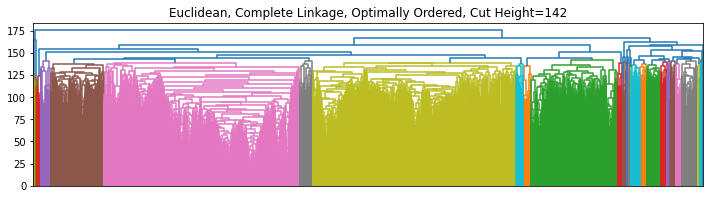

In [855]:
fig = plt.figure(figsize=(12, 3))  
fig.patch.set_facecolor('white')

cut_height = 142
d = hierarchy.dendrogram(Z_opt, no_labels=True, color_threshold=cut_height)

plt.title('Euclidean, Complete Linkage, Optimally Ordered, Cut Height=%s' %cut_height)

In [383]:
euc_gs_order = geneset_order_sampfiltered[opt_leaves]

Text(0.5, 1.04, 'Euclidean, Complete Linkage, Optimally Ordered, ALL Themes')

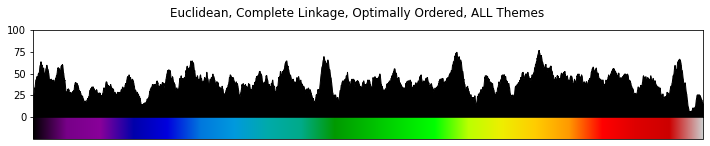

In [976]:
window_size = 100
term_gs_inds = np.array([])


title = 'Immune Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'IMMUN') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'INTERLEUKIN') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'INTERFERON') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'B_CELL') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'T_CELL') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'LYMPHOCYTE') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'NEUTROPHIL') > -1)[0]
)

title = 'Cardiac Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'CARD') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'HEART') > -1)[0]
)

title = 'Neural Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'BRAIN') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'NEUR') > -1)[0]
)

title = 'Development/Differentiation Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'DEVELOPMENT') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'DIFFERENTIATION') > -1)[0]
)

title = 'Cell Cycle Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'CELL_CYCLE') > -1)[0]
)

# title = 'Viral Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(euc_gs_order, 'VIRUS') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(euc_gs_order, 'VIRAL') > -1)[0]
# )

title = 'Lipid Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'LIPID') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'FATTY_ACID') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'STEROID') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'HORMONE') > -1)[0]
)

title = 'Ion Transport Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(
        (np.char.find(euc_gs_order, 'TRANSPORT') > -1) & 
        (np.char.find(euc_gs_order, '_ION') > -1)
    )[0]
)

title = 'Muscle Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'MUSCLE') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'MUSCUL') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'MYO') > -1)[0]
)

title = 'DNA Repair Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(
        (np.char.find(euc_gs_order, 'DNA') > -1) & 
        (np.char.find(euc_gs_order, 'REPAIR') > -1)
    )[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(
        (np.char.find(euc_gs_order, 'DNA') > -1) & 
        (np.char.find(euc_gs_order, 'DAMAGE') > -1)
    )[0]
)

# title = 'Blood Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(euc_gs_order, 'BLOOD') > -1)[0]
# )

title = 'Renal Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'KIDNEY') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'RENAL') > -1)[0]
)

title = 'Signaling Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'SIGNAL') > -1)[0]
)

title = 'Metabolic Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'METABOL') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(euc_gs_order, 'CATABOL') > -1)[0]
)


title = 'ALL Themes'


term_gs_inds = np.unique(term_gs_inds)
spectrum_sums = []
for i in range(len(euc_gs_order)):
    test_inds = np.arange(i - int(window_size / 2), i + int(window_size / 2))
    count = np.count_nonzero(np.isin(test_inds, term_gs_inds))
    spectrum_sums.append(count)
    
    


fig, axes = plt.subplots(2, 1, figsize=(12, 2), gridspec_kw={'height_ratios': [4, 1]})  
fig.patch.set_facecolor('white')
plt.subplots_adjust(hspace=0)

axes.ravel()

axes[0].fill_between(range(len(spectrum_sums)), spectrum_sums, color='k')
axes[0].set_xticks([])
axes[0].set_xlim([0, len(spectrum_sums)])
axes[0].set_ylim([0, window_size])

colors = cm.get_cmap('nipy_spectral', len(euc_gs_order))
matplotlib.colorbar.ColorbarBase(axes[1], cmap=colors, orientation='horizontal').set_ticks([])
# axes[1].set_xticklabels(spectrum_labels, rotation=45, ha='right')

fig.suptitle('Euclidean, Complete Linkage, Optimally Ordered, ' + title, y=1.04)

In [977]:
len(term_gs_inds)

3119

In [357]:
Z_cut = hierarchy.cut_tree(Z, height=cut_height).flatten()

In [377]:
for i in range(np.max(Z_cut) + 1)[:7]:
    cluster_gs_inds = np.where(Z_cut == i)[0]
    

In [438]:
# for i in geneset_order_sampfiltered[cluster_gs_inds]:
#     print(i)

In [443]:
for i in geneset_order_sampfiltered[opt_leavs]:
    print(i)

GOBP_REGULATION_OF_ASTROCYTE_ACTIVATION
GOBP_NEGATIVE_REGULATION_OF_ASTROCYTE_ACTIVATION
GOBP_NEGATIVE_REGULATION_OF_MICROGLIAL_CELL_ACTIVATION
GOBP_NEGATIVE_REGULATION_OF_NEUROINFLAMMATORY_RESPONSE
GOBP_NEGATIVE_REGULATION_OF_MACROPHAGE_ACTIVATION
GOBP_AMYLOID_BETA_CLEARANCE_BY_CELLULAR_CATABOLIC_PROCESS
GOBP_POSITIVE_REGULATION_OF_PROTEIN_CATABOLIC_PROCESS_IN_THE_VACUOLE
GOBP_REGULATION_OF_LYSOSOMAL_PROTEIN_CATABOLIC_PROCESS
GOBP_REGULATION_OF_PROTEIN_CATABOLIC_PROCESS_IN_THE_VACUOLE
GOBP_PROTEIN_CATABOLIC_PROCESS_IN_THE_VACUOLE
GOBP_LYSOSOMAL_PROTEIN_CATABOLIC_PROCESS
GOBP_AMYLOID_FIBRIL_FORMATION
GOBP_REGULATION_OF_AMYLOID_FIBRIL_FORMATION
GOBP_NEGATIVE_REGULATION_OF_AMYLOID_FIBRIL_FORMATION
GOBP_NEGATIVE_REGULATION_OF_RECEPTOR_RECYCLING
GOBP_NEGATIVE_REGULATION_OF_LOW_DENSITY_LIPOPROTEIN_PARTICLE_CLEARANCE
GOBP_NEGATIVE_REGULATION_OF_LIPOPROTEIN_PARTICLE_CLEARANCE
GOBP_REGULATION_OF_LOW_DENSITY_LIPOPROTEIN_PARTICLE_CLEARANCE
GOBP_REGULATION_OF_LIPOPROTEIN_PARTICLE_CLEARANCE
GOBP_P

GOBP_NEUROTRANSMITTER_TRANSPORT
GOBP_NEUROTRANSMITTER_SECRETION
GOBP_SYNAPTIC_VESICLE_EXOCYTOSIS
GOBP_VESICLE_MEDIATED_TRANSPORT_IN_SYNAPSE
GOBP_AMINE_TRANSPORT
GOBP_MONOAMINE_TRANSPORT
GOBP_CATECHOLAMINE_TRANSPORT
GOBP_CATECHOLAMINE_SECRETION
GOBP_DOPAMINE_SECRETION
GOBP_DOPAMINE_TRANSPORT
GOBP_REGULATION_OF_NEUROTRANSMITTER_RECEPTOR_ACTIVITY
GOBP_REGULATION_OF_SIGNALING_RECEPTOR_ACTIVITY
GOBP_SYNAPTIC_TRANSMISSION_GLUTAMATERGIC
GOBP_REGULATION_OF_SYNAPTIC_TRANSMISSION_GLUTAMATERGIC
GOBP_POSITIVE_REGULATION_OF_SYNAPTIC_TRANSMISSION_GLUTAMATERGIC
GOBP_CILIUM_MOVEMENT
GOBP_CILIUM_OR_FLAGELLUM_DEPENDENT_CELL_MOTILITY
GOBP_SPERM_MOTILITY
GOBP_SPERMATID_DIFFERENTIATION
GOBP_MEMORY
GOBP_COGNITION
GOBP_LEARNING
GOBP_REGULATION_OF_SYNAPTIC_PLASTICITY
GOBP_POSITIVE_REGULATION_OF_SYNAPTIC_TRANSMISSION
GOBP_LONG_TERM_SYNAPTIC_POTENTIATION
GOBP_REGULATION_OF_NERVOUS_SYSTEM_PROCESS
GOBP_REGULATION_OF_POSTSYNAPTIC_MEMBRANE_POTENTIAL
GOBP_CHEMICAL_SYNAPTIC_TRANSMISSION_POSTSYNAPTIC
GOBP_SENSORY_PERC

In [381]:
distance_cos = pdist(all_orders_log2ooe_sampfiltered, metric='cosine')
Z_cos = hierarchy.complete(distance_cos)
Z_cos_opt = hierarchy.optimal_leaf_ordering(Z_cos, distance_cos)
cos_opt_leaves = hierarchy.leaves_list(Z_cos_opt)

Text(0.5, 1.0, 'Cosine, Complete Linkage, Optimally Ordered, Cut Height=0.98')

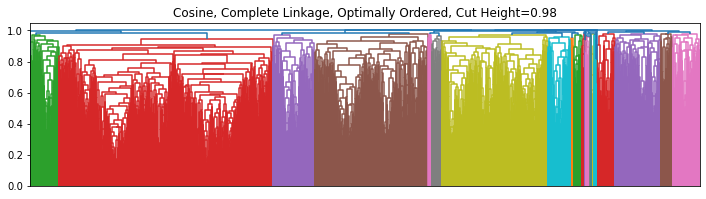

In [854]:
fig = plt.figure(figsize=(12, 3))  
fig.patch.set_facecolor('white')

cut_height = 0.98
d = hierarchy.dendrogram(Z_cos_opt, no_labels=True, color_threshold=cut_height)
plt.title('Cosine, Complete Linkage, Optimally Ordered, Cut Height=%s' %cut_height)

In [543]:
cos_cut = hierarchy.cut_tree(Z_cos, height=cut_height).flatten()
np.bincount(cos_cut == 2)

array([ 258,  316, 2479,  325,  135, 1226,   96,  482,   36, 1316,   43,
        529,   40,  208,  121,   19,   38,    9,    7,    6,   37,    6,
          9,    5,    1])

In [559]:
x = cos_gs_order[np.where(np.isin(cos_opt_leaves, np.where(cos_cut == 2)[0]))[0]]

In [587]:
for i in x:
    print(i)

GOBP_NEGATIVE_REGULATION_OF_TROPHOBLAST_CELL_MIGRATION
GOBP_GLUTATHIONE_TRANSPORT
GOBP_GLUTATHIONE_TRANSMEMBRANE_TRANSPORT
GOBP_POSITIVE_REGULATION_OF_NON_CANONICAL_WNT_SIGNALING_PATHWAY
GOBP_REGULATION_OF_NON_CANONICAL_WNT_SIGNALING_PATHWAY
GOBP_REGULATION_OF_WNT_SIGNALING_PATHWAY_PLANAR_CELL_POLARITY_PATHWAY
GOBP_POSITIVE_REGULATION_OF_WNT_SIGNALING_PATHWAY_PLANAR_CELL_POLARITY_PATHWAY
GOBP_POSITIVE_REGULATION_OF_RESPONSE_TO_OXIDATIVE_STRESS
GOBP_POSITIVE_REGULATION_OF_RESPONSE_TO_REACTIVE_OXYGEN_SPECIES
GOBP_POSITIVE_REGULATION_OF_HYDROGEN_PEROXIDE_MEDIATED_PROGRAMMED_CELL_DEATH
GOBP_POSITIVE_REGULATION_OF_MICROTUBULE_BINDING
GOBP_REGULATION_OF_MICROTUBULE_BINDING
GOBP_MITOCHONDRIAL_RESPIRASOME_ASSEMBLY
GOBP_MITOCHONDRIAL_ELECTRON_TRANSPORT_CYTOCHROME_C_TO_OXYGEN
GOBP_RRNA_PSEUDOURIDINE_SYNTHESIS
GOBP_PSEUDOURIDINE_SYNTHESIS
GOBP_TELOMERASE_RNA_LOCALIZATION
GOBP_POSITIVE_REGULATION_OF_TELOMERASE_RNA_LOCALIZATION_TO_CAJAL_BODY
GOBP_NUCLEOLAR_CHROMATIN_ORGANIZATION
GOBP_NUCLEOLUS_ORGA

In [551]:
2809 - 330

2479

In [548]:
geneset_order_sampfiltered[np.where(np.isin(cos_opt_leaves, np.where(cos_cut == 2)[0]))[0]]

array(['GOBP_AXON_MIDLINE_CHOICE_POINT_RECOGNITION',
       'GOBP_AXO_DENDRITIC_PROTEIN_TRANSPORT',
       'GOBP_AXO_DENDRITIC_TRANSPORT', ..., 'GOBP_NAD_TRANSPORT',
       'GOBP_NAIL_DEVELOPMENT', 'GOBP_NATURAL_KILLER_CELL_ACTIVATION'],
      dtype='<U148')

In [544]:
np.where(cos_cut == 2)[0]

array([   2,   21,   23, ..., 7731, 7740, 7746])

In [401]:
cos_gs_order = geneset_order_sampfiltered[cos_opt_leaves]

In [429]:
cos_gs_order

array(['GOBP_SRP_DEPENDENT_COTRANSLATIONAL_PROTEIN_TARGETING_TO_MEMBRANE_SIGNAL_SEQUENCE_RECOGNITION',
       'GOBP_NEGATIVE_REGULATION_OF_PROTEIN_TARGETING_TO_MITOCHONDRION',
       'GOBP_NEGATIVE_REGULATION_OF_ESTABLISHMENT_OF_PROTEIN_LOCALIZATION_TO_MITOCHONDRION',
       ..., 'GOBP_AUTOPHAGOSOME_MEMBRANE_DOCKING',
       'GOBP_CALCIUM_ION_IMPORT_INTO_SARCOPLASMIC_RETICULUM',
       'GOBP_REGULATION_OF_CARDIAC_MUSCLE_CELL_MEMBRANE_POTENTIAL'],
      dtype='<U148')

Text(0.5, 1.04, 'Cosine, Complete Linkage, Optimally Ordered, Metabolic Genesets')

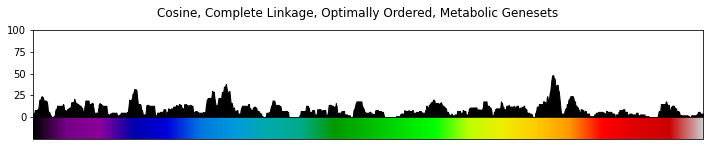

In [862]:
window_size = 100
term_gs_inds = np.array([])


# title = 'Immune Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'IMMUN') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'INTERLEUKIN') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'INTERFERON') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'B_CELL') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'T_CELL') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'LYMPHOCYTE') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'NEUTROPHIL') > -1)[0]
# )

# title = 'Cardiac Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'CARD') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'HEART') > -1)[0]
# )

# title = 'Neural Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'BRAIN') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'NEUR') > -1)[0]
# )

# title = 'Development/Differentiation Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'DEVELOPMENT') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'DIFFERENTIATION') > -1)[0]
# )

# title = 'Cell Cycle Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'CELL_CYCLE') > -1)[0]
# )

# # title = 'Viral Genesets'
# # term_gs_inds = np.append(
# #     term_gs_inds, np.where(np.char.find(cos_gs_order, 'VIRUS') > -1)[0]
# # )
# # term_gs_inds = np.append(
# #     term_gs_inds, np.where(np.char.find(cos_gs_order, 'VIRAL') > -1)[0]
# # )

# title = 'Lipid Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'LIPID') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'FATTY_ACID') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'STEROID') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'HORMONE') > -1)[0]
# )

# title = 'Ion Transport Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(
#         (np.char.find(cos_gs_order, 'TRANSPORT') > -1) & 
#         (np.char.find(cos_gs_order, '_ION') > -1)
#     )[0]
# )

# title = 'Muscle Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'MUSCLE') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'MUSCUL') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'MYO') > -1)[0]
# )

# title = 'DNA Repair Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(
#         (np.char.find(cos_gs_order, 'DNA') > -1) & 
#         (np.char.find(cos_gs_order, 'REPAIR') > -1)
#     )[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(
#         (np.char.find(cos_gs_order, 'DNA') > -1) & 
#         (np.char.find(cos_gs_order, 'DAMAGE') > -1)
#     )[0]
# )

# # title = 'Blood Genesets'
# # term_gs_inds = np.append(
# #     term_gs_inds, np.where(np.char.find(cos_gs_order, 'BLOOD') > -1)[0]
# # )

# title = 'Renal Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'KIDNEY') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'RENAL') > -1)[0]
# )

# title = 'Signaling Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'SIGNAL') > -1)[0]
# )

# title = 'Protein Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos_gs_order, 'PROTEIN') > -1)[0]
# )

title = 'Metabolic Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(cos_gs_order, 'METABOL') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(cos_gs_order, 'CATABOL') > -1)[0]
)


# title = 'ALL Themes'



term_gs_inds = np.unique(term_gs_inds)
spectrum_sums = []
for i in range(len(cos_gs_order)):
    test_inds = np.arange(i - int(window_size / 2), i + int(window_size / 2))
    count = np.count_nonzero(np.isin(test_inds, term_gs_inds))
    spectrum_sums.append(count)
    
    


fig, axes = plt.subplots(2, 1, figsize=(12, 2), gridspec_kw={'height_ratios': [4, 1]})  
fig.patch.set_facecolor('white')
plt.subplots_adjust(hspace=0)

axes.ravel()

axes[0].fill_between(range(len(spectrum_sums)), spectrum_sums, color='k')
axes[0].set_xticks([])
axes[0].set_xlim([0, len(spectrum_sums)])
axes[0].set_ylim([0, window_size])

colors = cm.get_cmap('nipy_spectral', len(cos_gs_order))
matplotlib.colorbar.ColorbarBase(axes[1], cmap=colors, orientation='horizontal').set_ticks([])
# axes[1].set_xticklabels(spectrum_labels, rotation=45, ha='right')

fig.suptitle('Cosine, Complete Linkage, Optimally Ordered, ' + title, y=1.04)

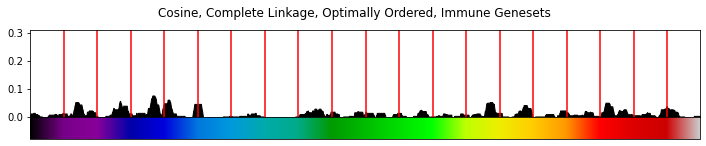

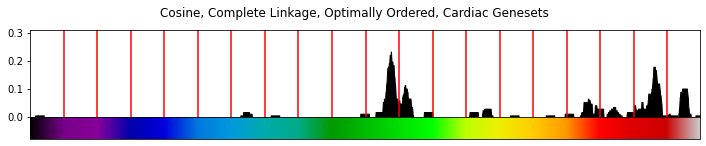

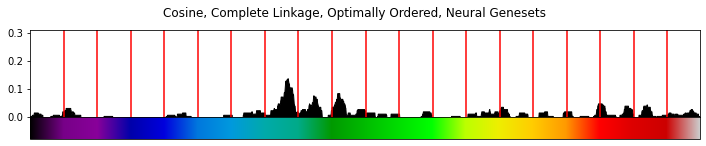

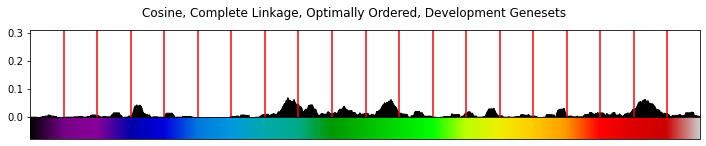

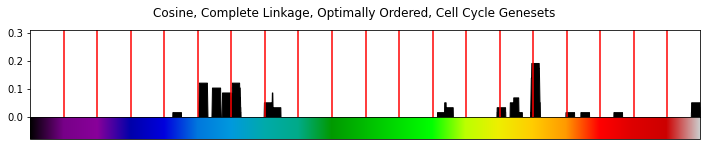

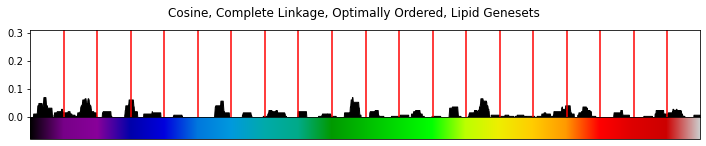

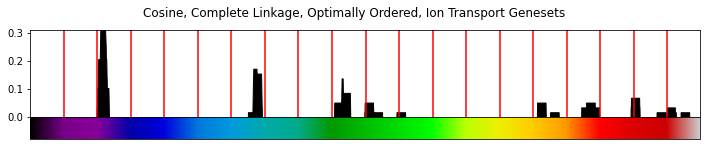

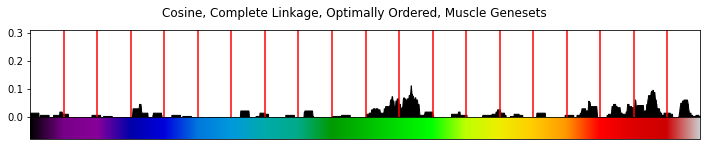

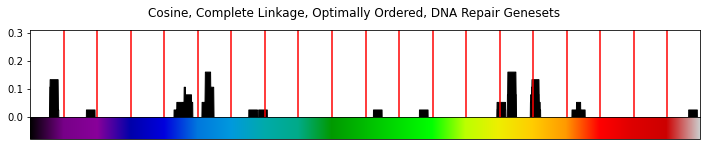

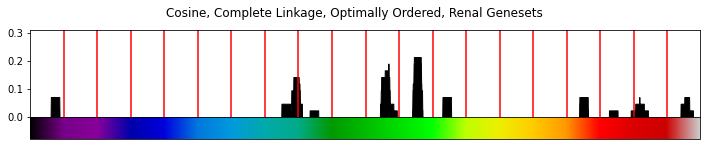

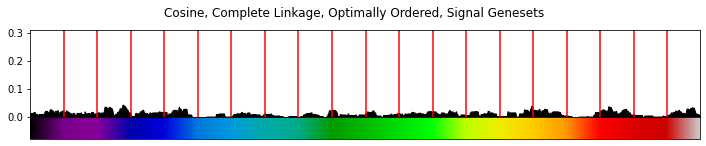

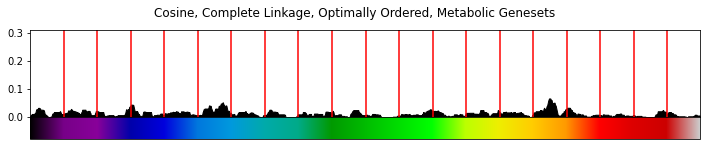

In [960]:
# window_size = 100



# title = 'Immune Genesets'
# term_gs_inds_immune = np.array([])
# term_gs_inds_immune = np.append(
#     term_gs_inds_immune, np.where(np.char.find(cos_gs_order, 'IMMUN') > -1)[0]
# )
# term_gs_inds_immune = np.append(
#     term_gs_inds_immune, np.where(np.char.find(cos_gs_order, 'INTERLEUKIN') > -1)[0]
# )
# term_gs_inds_immune = np.append(
#     term_gs_inds_immune, np.where(np.char.find(cos_gs_order, 'INTERFERON') > -1)[0]
# )
# term_gs_inds_immune = np.append(
#     term_gs_inds_immune, np.where(np.char.find(cos_gs_order, 'B_CELL') > -1)[0]
# )
# term_gs_inds_immune = np.append(
#     term_gs_inds_immune, np.where(np.char.find(cos_gs_order, 'T_CELL') > -1)[0]
# )
# term_gs_inds_immune = np.append(
#     term_gs_inds_immune, np.where(np.char.find(cos_gs_order, 'LYMPHOCYTE') > -1)[0]
# )
# term_gs_inds_immune = np.append(
#     term_gs_inds_immune, np.where(np.char.find(cos_gs_order, 'NEUTROPHIL') > -1)[0]
# )
# term_gs_inds_immune = np.unique(term_gs_inds_immune)

# title = 'Cardiac Genesets'
# term_gs_inds_card = np.array([])
# term_gs_inds_card = np.append(
#     term_gs_inds_card, np.where(np.char.find(cos_gs_order, 'CARD') > -1)[0]
# )
# term_gs_inds_card = np.append(
#     term_gs_inds_card, np.where(np.char.find(cos_gs_order, 'HEART') > -1)[0]
# )
# term_gs_inds_card = np.unique(term_gs_inds_card)

# title = 'Neural Genesets'
# term_gs_inds_neur = np.array([])
# term_gs_inds_neur = np.append(
#     term_gs_inds_neur, np.where(np.char.find(cos_gs_order, 'BRAIN') > -1)[0]
# )
# term_gs_inds_neur = np.append(
#     term_gs_inds_neur, np.where(np.char.find(cos_gs_order, 'NEUR') > -1)[0]
# )
# term_gs_inds_neur = np.unique(term_gs_inds_neur)

# title = 'Development/Differentiation Genesets'
# term_gs_inds_dev = np.array([])
# term_gs_inds_dev = np.append(
#     term_gs_inds_dev, np.where(np.char.find(cos_gs_order, 'DEVELOPMENT') > -1)[0]
# )
# term_gs_inds_dev = np.append(
#     term_gs_inds_dev, np.where(np.char.find(cos_gs_order, 'DIFFERENTIATION') > -1)[0]
# )
# term_gs_inds_dev = np.unique(term_gs_inds_dev)

# title = 'Cell Cycle Genesets'
# term_gs_inds_cc = np.array([])
# term_gs_inds_cc = np.append(
#     term_gs_inds_cc, np.where(np.char.find(cos_gs_order, 'CELL_CYCLE') > -1)[0]
# )
# term_gs_inds_cc = np.unique(term_gs_inds_cc)

# title = 'Lipid Genesets'
# term_gs_inds_lipid = np.array([])
# term_gs_inds_lipid = np.append(
#     term_gs_inds_lipid, np.where(np.char.find(cos_gs_order, 'LIPID') > -1)[0]
# )
# term_gs_inds_lipid = np.append(
#     term_gs_inds_lipid, np.where(np.char.find(cos_gs_order, 'FATTY_ACID') > -1)[0]
# )
# term_gs_inds_lipid = np.append(
#     term_gs_inds_lipid, np.where(np.char.find(cos_gs_order, 'STEROID') > -1)[0]
# )
# term_gs_inds_lipid = np.append(
#     term_gs_inds_lipid, np.where(np.char.find(cos_gs_order, 'HORMONE') > -1)[0]
# )
# term_gs_inds_lipid = np.unique(term_gs_inds_lipid)

# title = 'Ion Transport Genesets'
# term_gs_inds_ion = np.array([])
# term_gs_inds_ion = np.append(
#     term_gs_inds_ion, np.where(
#         (np.char.find(cos_gs_order, 'TRANSPORT') > -1) & 
#         (np.char.find(cos_gs_order, '_ION') > -1)
#     )[0]
# )
# term_gs_inds_ion = np.unique(term_gs_inds_ion)

# title = 'Muscle Genesets'
# term_gs_inds_muscle = np.array([])
# term_gs_inds_muscle = np.append(
#     term_gs_inds_muscle, np.where(np.char.find(cos_gs_order, 'MUSCLE') > -1)[0]
# )
# term_gs_inds_muscle = np.append(
#     term_gs_inds_muscle, np.where(np.char.find(cos_gs_order, 'MUSCUL') > -1)[0]
# )
# term_gs_inds_muscle = np.append(
#     term_gs_inds_muscle, np.where(np.char.find(cos_gs_order, 'MYO') > -1)[0]
# )
# term_gs_inds_muscle = np.unique(term_gs_inds_muscle)

# title = 'DNA Repair Genesets'
# term_gs_inds_dna = np.array([])
# term_gs_inds_dna = np.append(
#     term_gs_inds_dna, np.where(
#         (np.char.find(cos_gs_order, 'DNA') > -1) & 
#         (np.char.find(cos_gs_order, 'REPAIR') > -1)
#     )[0]
# )
# term_gs_inds_dna = np.append(
#     term_gs_inds_dna, np.where(
#         (np.char.find(cos_gs_order, 'DNA') > -1) & 
#         (np.char.find(cos_gs_order, 'DAMAGE') > -1)
#     )[0]
# )
# term_gs_inds_dna = np.unique(term_gs_inds_dna)

# title = 'Renal Genesets'
# term_gs_inds_renal = np.array([])
# term_gs_inds_renal = np.append(
#     term_gs_inds_renal, np.where(np.char.find(cos_gs_order, 'KIDNEY') > -1)[0]
# )
# term_gs_inds_renal = np.append(
#     term_gs_inds_renal, np.where(np.char.find(cos_gs_order, 'RENAL') > -1)[0]
# )
# term_gs_inds_renal = np.unique(term_gs_inds_renal)

# title = 'Signaling Genesets'
# term_gs_inds_signal = np.array([])
# term_gs_inds_signal = np.append(
#     term_gs_inds_signal, np.where(np.char.find(cos_gs_order, 'SIGNAL') > -1)[0]
# )
# term_gs_inds_signal = np.unique(term_gs_inds_signal)

# title = 'Metabolic Genesets'
# term_gs_inds_metabolic = np.array([])
# term_gs_inds_metabolic = np.append(
#     term_gs_inds_metabolic, np.where(np.char.find(cos_gs_order, 'METABOL') > -1)[0]
# )
# term_gs_inds_metabolic = np.append(
#     term_gs_inds_metabolic, np.where(np.char.find(cos_gs_order, 'CATABOL') > -1)[0]
# )
# term_gs_inds_metabolic = np.unique(term_gs_inds_metabolic)

# theme_inds = [term_gs_inds_immune, term_gs_inds_card, term_gs_inds_neur, term_gs_inds_dev,
#              term_gs_inds_cc, term_gs_inds_lipid, term_gs_inds_ion, term_gs_inds_muscle,
#              term_gs_inds_dna, term_gs_inds_renal, term_gs_inds_signal, term_gs_inds_metabolic]
# themes = np.array(['Immune', 'Cardiac', 'Neural', 'Development', 'Cell Cycle', 'Lipid', 'Ion Transport', 'Muscle',
#           'DNA Repair', 'Renal', 'Signal', 'Metabolic'])

# # normal sum
# theme_spectrum_sums = []
# for term_gs_inds in theme_inds:
#     spectrum_sums = []
#     for i in range(len(cos_gs_order)):
#         test_inds = np.arange(i - int(window_size / 2), i + int(window_size / 2))
#         count = np.count_nonzero(np.isin(test_inds, term_gs_inds))
#         spectrum_sums.append(count)
#     theme_spectrum_sums.append(spectrum_sums)

# theme_spectrum_sums = np.array(theme_spectrum_sums)

# # fractional sum
# theme_spectrum_fract_sums = []
# for term_gs_inds in theme_inds:
#     spectrum_sums = []
#     for i in range(len(cos_gs_order)):
#         test_inds = np.arange(i - int(window_size / 2), i + int(window_size / 2))
#         count = np.count_nonzero(np.isin(test_inds, term_gs_inds))
#         spectrum_sums.append(count / len(term_gs_inds))
#     theme_spectrum_fract_sums.append(spectrum_sums)
    
# theme_spectrum_fract_sums = np.array(theme_spectrum_fract_sums)

for i in range(12):
    fig, axes = plt.subplots(2, 1, figsize=(12, 2), gridspec_kw={'height_ratios': [4, 1]})  
    fig.patch.set_facecolor('white')
    plt.subplots_adjust(hspace=0)

    axes.ravel()

    axes[0].fill_between(range(len(theme_spectrum_fract_sums[i])), theme_spectrum_fract_sums[i], color='k')
    axes[0].set_xticks([])
    axes[0].set_xlim([0, len(theme_spectrum_fract_sums[i])])
#     axes[0].set_ylim([0, window_size])
    axes[0].set_ylim([0, np.max(theme_spectrum_fract_sums)])
    
    for j in range(20):
        axes[0].plot([((j + 1) * 388), ((j + 1) * 388)], [0, np.max(theme_spectrum_fract_sums)], c='r')

    colors = cm.get_cmap('nipy_spectral', len(cos_gs_order))
    matplotlib.colorbar.ColorbarBase(axes[1], cmap=colors, orientation='horizontal').set_ticks([])
    # axes[1].set_xticklabels(spectrum_labels, rotation=45, ha='right')
    
    

    title = themes[i]
    fig.suptitle('Cosine, Complete Linkage, Optimally Ordered, %s Genesets' %title, y=1.04)
    
    plt.show()

In [970]:
theme_spectrum_sums.shape

(12, 7747)

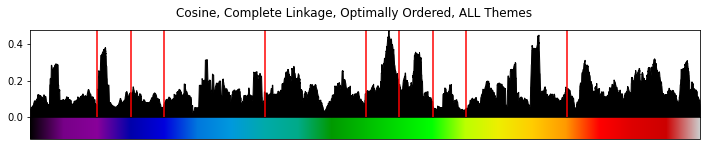

In [973]:
fig, axes = plt.subplots(2, 1, figsize=(12, 2), gridspec_kw={'height_ratios': [4, 1]})  
fig.patch.set_facecolor('white')
plt.subplots_adjust(hspace=0)

axes.ravel()

summed = np.sum(theme_spectrum_fract_sums, axis=0)
# summed = np.sum(theme_spectrum_sums, axis=0)

axes[0].fill_between(range(len(summed)), summed, color='k')
axes[0].set_xticks([])
axes[0].set_xlim([0, len(summed)])
#     axes[0].set_ylim([0, window_size])
axes[0].set_ylim([0, np.max(summed)])

for j in [1, 2, 3, 6, 9, 10, 11, 12, 15]: # [1, 2, 3, 6, 9, 10, 11, 12, 15]
    axes[0].plot([((j + 1) * 388), ((j + 1) * 388)], [0, np.max(summed)], c='r')

colors = cm.get_cmap('nipy_spectral', len(cos_gs_order))
matplotlib.colorbar.ColorbarBase(axes[1], cmap=colors, orientation='horizontal').set_ticks([])
# axes[1].set_xticklabels(spectrum_labels, rotation=45, ha='right')



title = themes[i]
fig.suptitle('Cosine, Complete Linkage, Optimally Ordered, ALL Themes', y=1.04)

plt.show()

In [954]:
top_themes_per_section_fract = []
for i in range(20):
    section_sum = np.sum(theme_spectrum_fract_sums[:, (i * 388):((i + 1) * 388)], axis=1)
    top_themes_per_section_fract.append(np.argsort(-section_sum))
top_themes_per_section_fract = np.array(top_themes_per_section_fract)

In [955]:
themes[top_themes_per_section_fract[:, 0:3]]

array([['DNA Repair', 'Lipid', 'Renal'],
       ['Lipid', 'Immune', 'Metabolic'],
       ['Ion Transport', 'Signal', 'Immune'],
       ['Immune', 'Muscle', 'Metabolic'],
       ['DNA Repair', 'Immune', 'Signal'],
       ['Cell Cycle', 'DNA Repair', 'Metabolic'],
       ['Ion Transport', 'Cell Cycle', 'DNA Repair'],
       ['Neural', 'Renal', 'Development'],
       ['Neural', 'Development', 'Immune'],
       ['Ion Transport', 'Neural', 'Development'],
       ['Cardiac', 'Renal', 'Muscle'],
       ['Renal', 'Muscle', 'Cardiac'],
       ['Renal', 'Cell Cycle', 'Signal'],
       ['Lipid', 'Immune', 'Metabolic'],
       ['DNA Repair', 'Cell Cycle', 'Immune'],
       ['Cell Cycle', 'Metabolic', 'DNA Repair'],
       ['Cardiac', 'Ion Transport', 'Muscle'],
       ['Immune', 'Muscle', 'Signal'],
       ['Cardiac', 'Muscle', 'Development'],
       ['Cardiac', 'Muscle', 'Renal']], dtype='<U13')

In [956]:
top_themes_per_section = []
for i in range(20):
    section_sum = np.sum(theme_spectrum_sums[:, (i * 388):((i + 1) * 388)], axis=1)
    top_themes_per_section.append(np.argsort(-section_sum))
top_themes_per_section = np.array(top_themes_per_section)

In [957]:
themes[top_themes_per_section[:, 0:3]]

array([['Metabolic', 'Signal', 'Lipid'],
       ['Metabolic', 'Immune', 'Signal'],
       ['Signal', 'Immune', 'Metabolic'],
       ['Immune', 'Development', 'Metabolic'],
       ['Metabolic', 'Immune', 'Signal'],
       ['Metabolic', 'Cell Cycle', 'Lipid'],
       ['Metabolic', 'Signal', 'Development'],
       ['Development', 'Neural', 'Metabolic'],
       ['Development', 'Metabolic', 'Immune'],
       ['Development', 'Neural', 'Metabolic'],
       ['Development', 'Cardiac', 'Muscle'],
       ['Muscle', 'Metabolic', 'Development'],
       ['Metabolic', 'Signal', 'Development'],
       ['Metabolic', 'Development', 'Immune'],
       ['Metabolic', 'Signal', 'Immune'],
       ['Metabolic', 'Signal', 'Development'],
       ['Metabolic', 'Development', 'Muscle'],
       ['Signal', 'Immune', 'Development'],
       ['Development', 'Muscle', 'Cardiac'],
       ['Signal', 'Development', 'Muscle']], dtype='<U13')

In [1633]:
# chose representative based on term enrichment
bad_terms = ['THE', 'OF', 'VS', 'UP', 'DN', 'ACTIVITY', 'TO', 'IN', 
             'N', 'TARGETS', 'TARGET', 'AND', 'BINDING', 
             'PROCESS', 'OK', 'GOBP', 'RESPONSE', 'POSITIVE', 'NEGATIVE', 'BY']

def term_enrichment(genesets, window_size=100, discarded_terms=bad_terms, min_count=0):
    # cut the terms apart from each geneset
    gs_terms_cut = np.concatenate(np.char.split(genesets, '_'))
    # count the occurrence of each term 
    gs_terms, gs_term_counts = np.unique(
        gs_terms_cut[~np.isin(gs_terms_cut, discarded_terms)],
        return_counts=True
    )
    # expected term frequency
    exp = gs_term_counts / np.sum(gs_term_counts)
    
    group_info = []
    for i in range(0, len(genesets), window_size):
        grouped_geneset_names = genesets[i:(i + window_size)]
        
        # get terms in geneset names
        group_terms_full = np.concatenate(np.char.split(grouped_geneset_names, '_'))
        group_terms_full = group_terms_full[~np.isin(group_terms_full, discarded_terms)]
        
        # calculate observed over expected
        group_terms, group_term_counts = np.unique(group_terms_full, return_counts=True)
        group_term_obs = group_term_counts / np.sum(group_term_counts)
        group_term_exp = exp[np.isin(gs_terms, group_terms)]
        group_term_ooe = np.log2(group_term_obs / group_term_exp)
        
        # eliminate terms that just show up min_count times
        group_term_ooe = np.where(group_term_counts >= min_count, group_term_ooe, 0)
        group_term_ooe = np.where(group_term_ooe > 0, group_term_ooe, 0)
        num_pos_enriched = np.count_nonzero(group_term_ooe > 0)
        top_ooe_terms = group_terms[np.argsort(-group_term_ooe)[:num_pos_enriched]]
        top_count_terms = group_terms[np.argsort(-group_term_counts)[:num_pos_enriched]]
        
        # find the total enrichment of all terms in each geneset
        group_geneset_totalenrich = np.zeros(len(grouped_geneset_names))
        for name_ind in range(len(grouped_geneset_names)):
            name = grouped_geneset_names[name_ind]
            name_terms = np.array(name.split('_'))
            name_terms = name_terms[~np.isin(name_terms, discarded_terms)]
            group_geneset_totalenrich[name_ind] = np.sum(group_term_ooe[np.isin(group_terms, name_terms)])
        
        # get representative geneset
        rep = grouped_geneset_names[np.argsort(-group_geneset_totalenrich)[:3]]
        
        group_info.append([rep, top_ooe_terms, top_count_terms])
    
    group_info = np.array(group_info)
    return group_info

In [1492]:
window_size = 388*2
min_count=40
ind = 1

In [1493]:
# cut the terms apart from each geneset
gs_terms_cut = np.concatenate(np.char.split(cos_gs_order, '_'))
# count the occurrence of each term 
gs_terms, gs_term_counts = np.unique(
    gs_terms_cut[~np.isin(gs_terms_cut, discarded_terms)],
    return_counts=True
)
# expected term frequency
exp = gs_term_counts / np.sum(gs_term_counts)

group_info = []
for i in range(0, len(cos_gs_order), window_size)[ind:ind+1]:
    grouped_geneset_names = cos_gs_order[i:(i + window_size)]

    # get terms in geneset names
    group_terms_full = np.concatenate(np.char.split(grouped_geneset_names, '_'))
    group_terms_full = group_terms_full[~np.isin(group_terms_full, discarded_terms)]

    # calculate observed over expected
    group_terms, group_term_counts = np.unique(group_terms_full, return_counts=True)
    group_term_obs = group_term_counts / np.sum(group_term_counts)
    group_term_exp = exp[np.isin(gs_terms, group_terms)]
    group_term_ooe = np.log2(group_term_obs / group_term_exp)

    # eliminate terms that just show up once
    group_term_ooe = np.where(group_term_counts >= min_count, group_term_ooe, 0)
    group_term_ooe = np.where(group_term_ooe > 0, group_term_ooe, 0)
    top_ooe_terms = group_terms[np.argsort(-group_term_ooe)[:5]]
    top_count_terms = group_terms[np.argsort(-group_term_counts)[:5]]

    # find the total enrichment of all terms in each geneset
    group_geneset_totalenrich = np.zeros(len(grouped_geneset_names))
    for name_ind in range(len(grouped_geneset_names)):
        name = grouped_geneset_names[name_ind]
        name_terms = np.array(name.split('_'))
        name_terms = name_terms[~np.isin(name_terms, discarded_terms)]
        group_geneset_totalenrich[name_ind] = np.sum(group_term_ooe[np.isin(group_terms, name_terms)])
        print(np.round(np.sum(group_term_ooe[np.isin(group_terms, name_terms)]), 4), '\t', name)

    # get representative geneset
    rep = grouped_geneset_names[np.argsort(-group_geneset_totalenrich)[0]]

    group_info.append([rep, top_ooe_terms, top_count_terms])
#     print(np.count_nonzero(group_term_ooe > 0))

group_info = np.array(group_info)

8
10
7
2
5
5
5
5
4
8


/tmp/ipykernel_86501/1692789099.py:46: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  group_info = np.array(group_info)


In [1469]:
group_terms[group_term_ooe > 0][o]

array(['T', 'CATABOLIC', 'PATHWAY', 'RESPONSE', 'SIGNALING', 'NEGATIVE',
       'REGULATION', 'TRANSPORT', 'POSITIVE'], dtype='<U17')

In [1470]:
group_term_counts[group_term_ooe > 0][o]

array([ 24,  26,  32,  42,  29,  42, 154,  20,  48])

In [1471]:
o = np.argsort(-group_term_ooe[group_term_ooe > 0])

In [1472]:
group_term_ooe[group_term_ooe > 0][o]

array([1.66477882, 1.0471949 , 0.5681705 , 0.31964334, 0.21356003,
       0.1560663 , 0.04529206, 0.04514374, 0.0146974 ])

In [1507]:
776*2

1552

In [1547]:
# cos_group_info = term_enrichment(cos_gs_order, window_size=388, discarded_terms=bad_terms, min_count=20) 
# euc_group_info = term_enrichment(euc_gs_order, window_size=388, discarded_terms=bad_terms, min_count=20) 
cos_group_info = term_enrichment(cos_gs_order, window_size=1552, discarded_terms=bad_terms, min_count=40) 
euc_group_info = term_enrichment(euc_gs_order, window_size=1552, discarded_terms=bad_terms, min_count=40)

/tmp/ipykernel_86501/58262319.py:51: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  group_info = np.array(group_info)


In [1419]:
cos_labels = ['Cell Migration', 'Metabolic', 'Ion Transport', 'Apoptosis', 'RRNA', 'Protein Localization/Metabolism', 'RNA', 'Neural', 'Myeloid', 'Secretion/Cell Processes', 'Development', 'Muscle', 'Organization/Assembly', 'Immune', 'Membrane', 'Metabolic', 'Molecular Transport', 'Muscle', 'Cardiac', 'Cell Respoonse']

In [1460]:
# using mean
for label, names, terms in zip(cos_labels, cos_group_info[:, 0], cos_group_info[:, 1]):
    print(label)
    print(names)
    print(terms)
    print()

Cell Migration
['GOBP_FIBROBLAST_MIGRATION' 'GOBP_MACROPHAGE_MIGRATION'
 'GOBP_TISSUE_MIGRATION']
['MIGRATION' 'BIOSYNTHETIC' 'NEGATIVE' 'METABOLIC' 'PATHWAY']

Metabolic
['GOBP_LEUKOTRIENE_CATABOLIC_PROCESS' 'GOBP_GLYCOLIPID_CATABOLIC_PROCESS'
 'GOBP_CERAMIDE_CATABOLIC_PROCESS']
['T' 'CATABOLIC' 'PATHWAY' 'PROTEIN' 'SIGNALING']

Ion Transport
['GOBP_CALCIUM_ION_TRANSPORT' 'GOBP_MONOATOMIC_ION_TRANSPORT'
 'GOBP_POSITIVE_REGULATION_OF_MONOATOMIC_ION_TRANSPORT']
['ION' 'CELLULAR' 'POSITIVE' 'TRANSPORT' 'SIGNALING']

Apoptosis
['GOBP_LEUKOCYTE_APOPTOTIC_PROCESS' 'GOBP_LYMPHOCYTE_APOPTOTIC_PROCESS'
 'GOBP_CHEMOKINE_PRODUCTION']
['APOPTOTIC' 'PRODUCTION' 'DIFFERENTIATION' 'NEGATIVE' 'CELL']

RRNA
['GOBP_RRNA_MODIFICATION' 'GOBP_RRNA_METHYLATION'
 'GOBP_DNA_CATABOLIC_PROCESS']
['RRNA' 'DNA' 'PRODUCTION' 'CATABOLIC' 'NEGATIVE']

Protein Localization/Metabolism
['GOBP_PROTEIN_CATABOLIC_PROCESS' 'GOBP_DNA_METABOLIC_PROCESS'
 'GOBP_PROTEIN_LOCALIZATION_TO_CHROMATIN']
['LOCALIZATION' 'ORGANIZATIO

In [1548]:
# using sum
for names, terms in zip(cos_group_info[:, 0], cos_group_info[:, 1]):
    print(names)
    print(terms)
    print()

['GOBP_NEGATIVE_REGULATION_OF_INTRINSIC_APOPTOTIC_SIGNALING_PATHWAY_IN_RESPONSE_TO_OSMOTIC_STRESS'
 'GOBP_POSITIVE_REGULATION_OF_INTRINSIC_APOPTOTIC_SIGNALING_PATHWAY'
 'GOBP_NEGATIVE_REGULATION_OF_OXIDATIVE_STRESS_INDUCED_INTRINSIC_APOPTOTIC_SIGNALING_PATHWAY']
['APOPTOTIC' 'ACTIVATION' 'PRODUCTION' 'ACID' 'SIGNALING' 'PATHWAY' 'ION'
 'BIOSYNTHETIC' 'MEDIATED' 'REGULATION' 'METABOLIC' 'TRANSPORT' 'CELL'
 'PROTEIN' 'CATABOLIC' 'CELLULAR']

['GOBP_PROTEIN_DNA_COMPLEX_SUBUNIT_ORGANIZATION'
 'GOBP_RNA_TEMPLATED_DNA_BIOSYNTHETIC_PROCESS'
 'GOBP_TRANSCRIPTION_DEPENDENT_TETHERING_OF_RNA_POLYMERASE_II_GENE_DNA_AT_NUCLEAR_PERIPHERY']
['RNA' 'DNA' 'LOCALIZATION' 'ORGANIZATION' 'CATABOLIC' 'PROTEIN'
 'METABOLIC' 'ASSEMBLY' 'DEVELOPMENT']

['GOBP_EPITHELIAL_CELL_PROLIFERATION_INVOLVED_IN_SALIVARY_GLAND_MORPHOGENESIS'
 'GOBP_CELL_PROLIFERATION_INVOLVED_IN_HEART_MORPHOGENESIS'
 'GOBP_NEGATIVE_REGULATION_OF_CELL_PROLIFERATION_INVOLVED_IN_HEART_MORPHOGENESIS']
['MORPHOGENESIS' 'DEVELOPMENT' 'MUSCLE' 

In [1417]:
euc_labels = ['Apoptosis', 'Cell Organization', 'Lymphoid Apoptosis', 'DNA', 'Signal Transduction', 'Immune', 'Cell organization', 'Cell Cycle', 'Morphogenesis', 'Mediated Signaling', 'Hormone', 'Transport/Metabolic', 'Catabolic', 'Differentiation', 'Morphogenesis', 'Cardiac', 'Development', 'Development', 'RRNA', 'Differentiation'] 

In [1418]:
# using mean
for label, names, terms in zip(euc_labels, euc_group_info[:, 0], euc_group_info[:, 1]):
    print(label)
    print(names)
    print(terms)
    print()

Apoptosis
['GOBP_APOPTOTIC_SIGNALING_PATHWAY'
 'GOBP_REGULATION_OF_APOPTOTIC_SIGNALING_PATHWAY'
 'GOBP_KERATINOCYTE_APOPTOTIC_PROCESS']
['APOPTOTIC' 'MUSCLE' 'CATABOLIC' 'PATHWAY' 'BIOSYNTHETIC']

Cell Organization
['GOBP_HETEROCHROMATIN_ORGANIZATION' 'GOBP_RUFFLE_ORGANIZATION'
 'GOBP_MICROVILLUS_ORGANIZATION']
['ORGANIZATION' 'METABOLIC' 'PATHWAY' '17' 'PEROXIDE']

Lymphoid Apoptosis
['GOBP_LYMPHOCYTE_APOPTOTIC_PROCESS' 'GOBP_LEUKOCYTE_APOPTOTIC_PROCESS'
 'GOBP_THYMOCYTE_APOPTOTIC_PROCESS']
['APOPTOTIC' 'MEDIATED' 'SIGNALING' 'NEGATIVE' 'REGULATION']

DNA
['GOBP_DNA_RECOMBINATION' 'GOBP_DNA_BIOSYNTHETIC_PROCESS'
 'GOBP_DNA_REPLICATION_INITIATION']
['DNA' 'SIGNALING' 'POSITIVE' 'PROTEIN' '1']

Signal Transduction
['GOBP_SIGNAL_RELEASE' 'GOBP_ARF_PROTEIN_SIGNAL_TRANSDUCTION'
 'GOBP_RAP_PROTEIN_SIGNAL_TRANSDUCTION']
['SIGNAL' 'MUSCLE' 'DEVELOPMENT' 'DIFFERENTIATION' 'METABOLIC']

Immune
['GOBP_IMMUNE_RESPONSE' 'GOBP_REGULATION_OF_IMMUNE_RESPONSE'
 'GOBP_ACTIVATION_OF_IMMUNE_RESPONSE']
['

In [1549]:
# using sum
for names, terms in zip(euc_group_info[:, 0], euc_group_info[:, 1]):
    print(names)
    print(terms)
    print()

['GOBP_REGULATION_OF_INTRINSIC_APOPTOTIC_SIGNALING_PATHWAY_IN_RESPONSE_TO_DNA_DAMAGE_BY_P53_CLASS_MEDIATOR'
 'GOBP_REGULATION_OF_INTRINSIC_APOPTOTIC_SIGNALING_PATHWAY_IN_RESPONSE_TO_DNA_DAMAGE'
 'GOBP_NEGATIVE_REGULATION_OF_INTRINSIC_APOPTOTIC_SIGNALING_PATHWAY_IN_RESPONSE_TO_DNA_DAMAGE']
['APOPTOTIC' 'LOCALIZATION' 'ACTIVATION' 'ASSEMBLY' 'DNA' 'SIGNALING'
 'PATHWAY' 'CATABOLIC' 'MEMBRANE' 'RECEPTOR' 'MEDIATED' 'BIOSYNTHETIC'
 'MUSCLE' 'PROTEIN' 'REGULATION']

['GOBP_REGULATION_OF_CELLULAR_RESPONSE_TO_TRANSFORMING_GROWTH_FACTOR_BETA_STIMULUS'
 'GOBP_POSITIVE_REGULATION_OF_TRANSCRIPTION_FROM_RNA_POLYMERASE_II_PROMOTER_INVOLVED_IN_CELLULAR_RESPONSE_TO_CHEMICAL_STIMULUS'
 'GOBP_REGULATION_OF_CELLULAR_RESPONSE_TO_GROWTH_FACTOR_STIMULUS']
['CYCLE' 'STIMULUS' 'ORGANIZATION' 'CELLULAR' 'ION' 'PROTEIN' 'CATABOLIC'
 'REGULATION' 'CELL' 'SIGNALING' 'METABOLIC' 'TRANSPORT' 'DEVELOPMENT']

['GOBP_ACID_SECRETION' 'GOBP_BILE_ACID_SECRETION'
 'GOBP_REGULATION_OF_BILE_ACID_SECRETION']
['SECRETION' 'A

In [440]:
# for i in geneset_order_sampfiltered[cos_opt_leavs]:
#     print(i)

All of order 4 by itself

In [1520]:
datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert/'
order = 4

order_f_format = 'hilbert_regions_order_4_search_space_c5GOBP_geneset_sampling.\d+_regions.100_sim_regions.CT20230608.npz'
for filename in os.listdir(datadir):
    if re.match(order_f_format, filename):
        order_f = filename

order4_log2ooe = np.load(datadir + order_f)['geneset_sampled_region_log2ooe']
    
    
# any under enrichment set to 0
order4_log2ooe = np.where(order4_log2ooe < 0, 0, order4_log2ooe)

# remove genesets that are never enriched
inds_to_keep = np.where(np.count_nonzero(order4_log2ooe, axis=1) > 0)[0]
order4_log2ooe_sampfiltered = order4_log2ooe[inds_to_keep]
geneset_order_4sampfiltered = geneset_order[inds_to_keep]

In [1521]:
order4_log2ooe_sampfiltered.shape

(7747, 2725)

In [1523]:
# Order 4 all
distance_4all_cos = pdist(order4_log2ooe_sampfiltered, metric='cosine')
Z_4all_cos = hierarchy.complete(distance_4all_cos)
Z_opt_4all_cos = hierarchy.optimal_leaf_ordering(Z_4all_cos, distance_4all_cos)
opt_leaves_4all_cos = hierarchy.leaves_list(Z_opt_4all_cos)

In [1615]:
datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert/'
out_f = datadir + 'hilbert_regions_order_4_search_space_c5GOBP_geneset_sampling.2725_regions.100_sim_regions.cosine.complete.opt.CT20230616.npz'

np.savez(out_f, distance=distance_4all_cos, Z=Z_4all_cos, Z_opt=Z_opt_4all_cos, opt_leaves=opt_leaves_4all_cos)

In [1525]:
cos4_gs_order = geneset_order_4sampfiltered[opt_leaves_4all_cos]

In [1524]:
# Order 4 all
distance_4all_euc = pdist(order4_log2ooe_sampfiltered, metric='euclidean')
Z_4all_euc = hierarchy.complete(distance_4all_euc)
Z_opt_4all_euc = hierarchy.optimal_leaf_ordering(Z_4all_euc, distance_4all_euc)
opt_leaves_4all_euc = hierarchy.leaves_list(Z_opt_4all_euc)

In [1526]:
euc4_gs_order = geneset_order_4sampfiltered[opt_leaves_4all_euc]

In [1550]:
cos4_group_info = term_enrichment(cos4_gs_order, window_size=776, discarded_terms=bad_terms, min_count=30) 
euc4_group_info = term_enrichment(euc4_gs_order, window_size=776, discarded_terms=bad_terms, min_count=30)

/tmp/ipykernel_86501/58262319.py:51: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  group_info = np.array(group_info)


In [1551]:
# using sum
for names, terms in zip(cos4_group_info[:, 0], cos4_group_info[:, 1]):
    print(names)
    print(terms)
    print()

['GOBP_POSITIVE_REGULATION_OF_TRANSMEMBRANE_RECEPTOR_PROTEIN_SERINE_THREONINE_KINASE_SIGNALING_PATHWAY'
 'GOBP_ADENYLATE_CYCLASE_INHIBITING_G_PROTEIN_COUPLED_GLUTAMATE_RECEPTOR_SIGNALING_PATHWAY'
 'GOBP_G_PROTEIN_COUPLED_GLUTAMATE_RECEPTOR_SIGNALING_PATHWAY']
['CELLULAR' 'RECEPTOR' 'CATABOLIC' 'PROTEIN' 'PATHWAY' 'SIGNALING' 'CELL'
 'REGULATION' 'METABOLIC']

['GOBP_REGULATION_OF_VITAMIN_D_BIOSYNTHETIC_PROCESS'
 'GOBP_REGULATION_OF_CARBOHYDRATE_BIOSYNTHETIC_PROCESS'
 'GOBP_POSITIVE_REGULATION_OF_MACROMOLECULE_BIOSYNTHETIC_PROCESS']
['BIOSYNTHETIC' 'METABOLIC' 'CELL' 'REGULATION']

['GOBP_NEGATIVE_REGULATION_OF_PERK_MEDIATED_UNFOLDED_PROTEIN_RESPONSE'
 'GOBP_REGULATION_OF_ENDOPLASMIC_RETICULUM_UNFOLDED_PROTEIN_RESPONSE'
 'GOBP_NEGATIVE_REGULATION_OF_ENDOPLASMIC_RETICULUM_UNFOLDED_PROTEIN_RESPONSE']
['PROTEIN' 'DIFFERENTIATION' 'REGULATION' 'CELL' 'DEVELOPMENT']

['GOBP_INNATE_IMMUNE_RESPONSE_ACTIVATING_SIGNALING_PATHWAY'
 'GOBP_IMMUNE_RESPONSE_REGULATING_SIGNALING_PATHWAY'
 'GOBP_IMMUNE

In [1552]:
# using sum
for names, terms in zip(euc4_group_info[:, 0], euc4_group_info[:, 1]):
    print(names)
    print(terms)
    print()

['GOBP_DNA_TEMPLATED_TRANSCRIPTION_ELONGATION'
 'GOBP_NEGATIVE_REGULATION_OF_DNA_TEMPLATED_TRANSCRIPTION_ELONGATION'
 'GOBP_POSITIVE_REGULATION_OF_DNA_DAMAGE_RESPONSE_SIGNAL_TRANSDUCTION_BY_P53_CLASS_MEDIATOR_RESULTING_IN_TRANSCRIPTION_OF_P21_CLASS_MEDIATOR']
['TRANSCRIPTION' 'DNA' 'MEDIATED' 'MEMBRANE' 'CATABOLIC' 'PATHWAY'
 'TRANSPORT' 'PROTEIN' 'SIGNALING' 'RECEPTOR']

['GOBP_EPITHELIAL_CELL_PROLIFERATION_INVOLVED_IN_SALIVARY_GLAND_MORPHOGENESIS'
 'GOBP_BLOOD_VESSEL_ENDOTHELIAL_CELL_PROLIFERATION_INVOLVED_IN_SPROUTING_ANGIOGENESIS'
 'GOBP_REGULATION_OF_STEM_CELL_PROLIFERATION']
['PROLIFERATION' 'MORPHOGENESIS' 'DIFFERENTIATION' 'CELL' 'INVOLVED'
 'DEVELOPMENT' 'REGULATION' 'PROTEIN']

['GOBP_CD4_POSITIVE_ALPHA_BETA_T_CELL_CYTOKINE_PRODUCTION'
 'GOBP_POSITIVE_REGULATION_OF_T_CELL_CYTOKINE_PRODUCTION'
 'GOBP_T_HELPER_2_CELL_CYTOKINE_PRODUCTION']
['PRODUCTION' 'T' 'CELLULAR' 'PROTEIN' 'RECEPTOR']

['GOBP_REGULATION_OF_CELL_GROWTH_INVOLVED_IN_CARDIAC_MUSCLE_CELL_DEVELOPMENT'
 'GOBP_NEGA

In [1553]:
cos4_group_info = term_enrichment(cos4_gs_order, window_size=1552, discarded_terms=bad_terms, min_count=40) 
euc4_group_info = term_enrichment(euc4_gs_order, window_size=1552, discarded_terms=bad_terms, min_count=40)

/tmp/ipykernel_86501/58262319.py:51: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  group_info = np.array(group_info)


In [1554]:
# using sum
for names, terms in zip(cos4_group_info[:, 0], cos4_group_info[:, 1]):
    print(names)
    print(terms)
    print()

['GOBP_REGULATION_OF_DNA_CATABOLIC_PROCESS'
 'GOBP_POSITIVE_REGULATION_OF_DNA_CATABOLIC_PROCESS'
 'GOBP_DNA_CATABOLIC_PROCESS']
['DNA' 'CATABOLIC' 'RECEPTOR' 'MEMBRANE' 'METABOLIC' 'CELLULAR'
 'BIOSYNTHETIC' 'PROTEIN' 'PATHWAY' 'CELL' 'SIGNALING' 'REGULATION'
 'INVOLVED']

['GOBP_PROTEIN_LIPID_COMPLEX_SUBUNIT_ORGANIZATION'
 'GOBP_REGULATION_OF_PERK_MEDIATED_UNFOLDED_PROTEIN_RESPONSE'
 'GOBP_NEGATIVE_REGULATION_OF_PERK_MEDIATED_UNFOLDED_PROTEIN_RESPONSE']
['PROTEIN' 'ORGANIZATION' 'MEDIATED' 'TRANSPORT' 'CELLULAR' 'SIGNALING'
 'ASSEMBLY' 'PATHWAY' 'REGULATION']

['GOBP_PROTEIN_DNA_COMPLEX_SUBUNIT_ORGANIZATION'
 'GOBP_AMINO_ACID_ACTIVATION' 'GOBP_PLASMA_MEMBRANE_RAFT_ORGANIZATION']
['ORGANIZATION' 'ACTIVATION' 'LOCALIZATION' 'DNA' 'CATABOLIC' 'TRANSPORT'
 'ACID' 'MEDIATED' 'METABOLIC' 'SIGNALING' 'MEMBRANE' 'PROTEIN' 'CELLULAR'
 'RECEPTOR' 'BIOSYNTHETIC' 'PATHWAY']

['GOBP_OPTIC_CUP_MORPHOGENESIS_INVOLVED_IN_CAMERA_TYPE_EYE_DEVELOPMENT'
 'GOBP_EPITHELIAL_CELL_PROLIFERATION_INVOLVED_IN_SA

In [1556]:
# using sum
for names, terms in zip(euc4_group_info[:, 0], euc4_group_info[:, 1]):
    print(names)
    print(terms)
    print()

['GOBP_INTRINSIC_APOPTOTIC_SIGNALING_PATHWAY_IN_RESPONSE_TO_DNA_DAMAGE_BY_P53_CLASS_MEDIATOR'
 'GOBP_POSITIVE_REGULATION_OF_INTRINSIC_APOPTOTIC_SIGNALING_PATHWAY_IN_RESPONSE_TO_DNA_DAMAGE'
 'GOBP_REGULATION_OF_INTRINSIC_APOPTOTIC_SIGNALING_PATHWAY_IN_RESPONSE_TO_DNA_DAMAGE_BY_P53_CLASS_MEDIATOR']
['DNA' 'APOPTOTIC' 'PROLIFERATION' 'MEDIATED' 'MEMBRANE' 'PATHWAY'
 'PROTEIN' 'CATABOLIC' 'TRANSPORT' 'RECEPTOR' 'SIGNALING' 'INVOLVED']

['GOBP_POSITIVE_REGULATION_OF_MYELOID_LEUKOCYTE_CYTOKINE_PRODUCTION_INVOLVED_IN_IMMUNE_RESPONSE'
 'GOBP_REGULATION_OF_CELL_GROWTH_INVOLVED_IN_CARDIAC_MUSCLE_CELL_DEVELOPMENT'
 'GOBP_POSITIVE_REGULATION_OF_CELL_GROWTH_INVOLVED_IN_CARDIAC_MUSCLE_CELL_DEVELOPMENT']
['PRODUCTION' 'MUSCLE' 'DEVELOPMENT' 'ION' 'DIFFERENTIATION' 'INVOLVED'
 'CELLULAR' 'CELL' 'ASSEMBLY' 'MORPHOGENESIS']

['GOBP_NEGATIVE_REGULATION_OF_CELL_PROLIFERATION_INVOLVED_IN_HEART_MORPHOGENESIS'
 'GOBP_POSITIVE_REGULATION_OF_EPITHELIAL_CELL_PROLIFERATION_INVOLVED_IN_LUNG_MORPHOGENESIS'
 'GOBP_

In [1607]:
cos4_group_info = term_enrichment(cos4_gs_order, window_size=1292, discarded_terms=bad_terms, min_count=40) 
euc4_group_info = term_enrichment(euc4_gs_order, window_size=1292, discarded_terms=bad_terms, min_count=40)

/tmp/ipykernel_86501/58262319.py:51: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  group_info = np.array(group_info)


In [1609]:
# using sum
for names, terms in zip(cos4_group_info[:, 0], cos4_group_info[:, 1]):
    print(names)
    print(terms)
    print()

['GOBP_REGULATION_OF_DNA_CATABOLIC_PROCESS'
 'GOBP_POSITIVE_REGULATION_OF_DNA_CATABOLIC_PROCESS'
 'GOBP_DNA_CATABOLIC_PROCESS_EXONUCLEOLYTIC']
['DNA' 'CATABOLIC' 'RECEPTOR' 'CELLULAR' 'METABOLIC' 'PATHWAY' 'PROTEIN'
 'CELL' 'SIGNALING' 'INVOLVED' 'REGULATION']

['GOBP_NEGATIVE_REGULATION_OF_INTRACELLULAR_PROTEIN_TRANSPORT'
 'GOBP_REGULATION_OF_INTRACELLULAR_PROTEIN_TRANSPORT'
 'GOBP_POSITIVE_REGULATION_OF_INTRACELLULAR_PROTEIN_TRANSPORT']
['PROTEIN' 'TRANSPORT' 'CELLULAR' 'REGULATION']

['GOBP_LYMPHOCYTE_ACTIVATION_INVOLVED_IN_IMMUNE_RESPONSE'
 'GOBP_ACTIVATION_OF_IMMUNE_RESPONSE'
 'GOBP_CELL_ACTIVATION_INVOLVED_IN_IMMUNE_RESPONSE']
['IMMUNE' 'ACTIVATION' 'ORGANIZATION' 'DNA' 'MEDIATED' 'ASSEMBLY'
 'PATHWAY' 'CATABOLIC' 'SIGNALING' 'TRANSPORT' 'RECEPTOR' 'REGULATION']

['GOBP_TRICARBOXYLIC_ACID_METABOLIC_PROCESS'
 'GOBP_ALPHA_LINOLENIC_ACID_METABOLIC_PROCESS'
 'GOBP_FATTY_ACID_DERIVATIVE_METABOLIC_PROCESS']
['ACID' 'METABOLIC' 'CATABOLIC' 'CELLULAR' 'PROTEIN' 'TRANSPORT'
 'BIOSYNTHETIC

Text(0.5, 1.04, 'Cosine, Order 4 Only, Complete Linkage, Optimally Ordered, Cardiac Genesets')

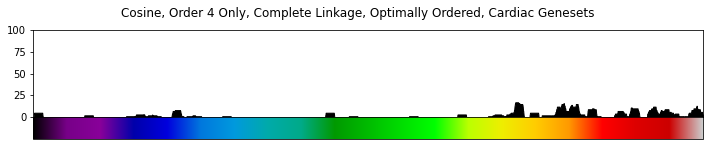

In [1614]:
window_size = 100
term_gs_inds = np.array([])


# title = 'Immune Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'IMMUN') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'INTERLEUKIN') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'INTERFERON') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'B_CELL') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'T_CELL') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'LYMPHOCYTE') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'NEUTROPHIL') > -1)[0]
# )

title = 'Cardiac Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(cos4_gs_order, 'CARD') > -1)[0]
)
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(cos4_gs_order, 'HEART') > -1)[0]
)

# title = 'Neural Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'BRAIN') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'NEUR') > -1)[0]
# )

# title = 'Development/Differentiation Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'DEVELOPMENT') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'DIFFERENTIATION') > -1)[0]
# )

# title = 'Cell Cycle Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'CELL_CYCLE') > -1)[0]
# )

# # title = 'Viral Genesets'
# # term_gs_inds = np.append(
# #     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'VIRUS') > -1)[0]
# # )
# # term_gs_inds = np.append(
# #     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'VIRAL') > -1)[0]
# # )

# title = 'Lipid Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'LIPID') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'FATTY_ACID') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'STEROID') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'HORMONE') > -1)[0]
# )

# title = 'Ion Transport Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(
#         (np.char.find(cos4_gs_order, 'TRANSPORT') > -1) & 
#         (np.char.find(cos4_gs_order, '_ION') > -1)
#     )[0]
# )

# title = 'Muscle Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'MUSCLE') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'MUSCUL') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'MYO') > -1)[0]
# )

# title = 'DNA Repair Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(
#         (np.char.find(cos4_gs_order, 'DNA') > -1) & 
#         (np.char.find(cos4_gs_order, 'REPAIR') > -1)
#     )[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(
#         (np.char.find(cos4_gs_order, 'DNA') > -1) & 
#         (np.char.find(cos4_gs_order, 'DAMAGE') > -1)
#     )[0]
# )

# # title = 'Blood Genesets'
# # term_gs_inds = np.append(
# #     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'BLOOD') > -1)[0]
# # )

# title = 'Renal Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'KIDNEY') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'RENAL') > -1)[0]
# )

# title = 'Signaling Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'SIGNAL') > -1)[0]
# )

# title = 'Protein Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'PROTEIN') > -1)[0]
# )

# title = 'Metabolic Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'METABOL') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(cos4_gs_order, 'CATABOL') > -1)[0]
# )


# title = 'ALL Themes'



term_gs_inds = np.unique(term_gs_inds)
spectrum_sums = []
for i in range(len(cos4_gs_order)):
    test_inds = np.arange(i - int(window_size / 2), i + int(window_size / 2))
    count = np.count_nonzero(np.isin(test_inds, term_gs_inds))
    spectrum_sums.append(count)
    
    


fig, axes = plt.subplots(2, 1, figsize=(12, 2), gridspec_kw={'height_ratios': [4, 1]})  
fig.patch.set_facecolor('white')
plt.subplots_adjust(hspace=0)

axes.ravel()

axes[0].fill_between(range(len(spectrum_sums)), spectrum_sums, color='k')
axes[0].set_xticks([])
axes[0].set_xlim([0, len(spectrum_sums)])
axes[0].set_ylim([0, window_size])

colors = cm.get_cmap('nipy_spectral', len(cos4_gs_order))
matplotlib.colorbar.ColorbarBase(axes[1], cmap=colors, orientation='horizontal').set_ticks([])
# axes[1].set_xticklabels(spectrum_labels, rotation=45, ha='right')

fig.suptitle('Cosine, Order 4 Only, Complete Linkage, Optimally Ordered, ' + title, y=1.04)

GPT UMAP from IJ

In [1624]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
path = datadir + 'c5GOBP_geneset_ordered.GPT.1D_UMAP.IJ20230616.tsv'

f = open(path)
lines = f.readlines()
f.close()

GPT_order_full = []
for line in lines[1:]:
    line = line.strip().split('\t')
    GPT_order_full.append(line)
GPT_order_full = np.array(GPT_order_full)
# GPT_order_full = np.loadtxt(path, delimiter='\t', dtype=str)

In [1626]:
GPT_order = GPT_order_full[:, 1]

In [1634]:
GPT_group_info = term_enrichment(GPT_order, window_size=1292, discarded_terms=bad_terms, min_count=40)

/tmp/ipykernel_86501/2417823062.py:51: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  group_info = np.array(group_info)


In [1635]:
# using sum
for names, terms in zip(GPT_group_info[:, 0], GPT_group_info[:, 1]):
    print(names)
    print(terms)
    print()

['GOBP_CELL_DIFFERENTIATION_INVOLVED_IN_EMBRYONIC_PLACENTA_DEVELOPMENT'
 'GOBP_EPITHELIAL_CELL_DIFFERENTIATION_INVOLVED_IN_KIDNEY_DEVELOPMENT'
 'GOBP_EPITHELIAL_CELL_DIFFERENTIATION_INVOLVED_IN_PROSTATE_GLAND_DEVELOPMENT']
['EMBRYONIC' 'MORPHOGENESIS' 'DEVELOPMENT' 'EPITHELIAL' 'FORMATION'
 'MIGRATION' 'NEURON' 'SYSTEM' 'DIFFERENTIATION' 'PROLIFERATION'
 'INVOLVED' 'CELL' 'MUSCLE']

['GOBP_REGULATION_OF_SMOOTH_MUSCLE_CELL_CHEMOTAXIS'
 'GOBP_T_CELL_ACTIVATION_INVOLVED_IN_IMMUNE_RESPONSE'
 'GOBP_POSITIVE_REGULATION_OF_MYELOID_LEUKOCYTE_CYTOKINE_PRODUCTION_INVOLVED_IN_IMMUNE_RESPONSE']
['HOMEOSTASIS' 'CHEMOTAXIS' 'IMMUNE' 'PRODUCTION' 'SMOOTH' 'T'
 'ACTIVATION' 'LEUKOCYTE' 'APOPTOTIC' 'MUSCLE' 'PROLIFERATION'
 'DIFFERENTIATION' 'CELL' 'MIGRATION' 'REGULATION' 'MEDIATED' 'INVOLVED']

['GOBP_TRANSFORMING_GROWTH_FACTOR_BETA_RECEPTOR_SIGNALING_PATHWAY'
 'GOBP_NEGATIVE_REGULATION_OF_EPIDERMAL_GROWTH_FACTOR_RECEPTOR_SIGNALING_PATHWAY'
 'GOBP_NEGATIVE_REGULATION_OF_INSULIN_LIKE_GROWTH_FACTOR_REC

In [2314]:
spectrum_sums_all = []

Text(0.5, 1.12, 'GPT Order, ALL Themes')

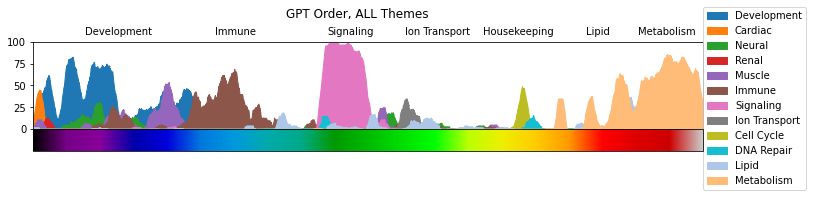

In [2354]:
# GPT ordering only
window_size = 100
term_gs_inds = np.array([])


# title = 'Immune Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'IMMUN') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'INTERLEUKIN') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'INTERFERON') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'B_CELL') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'T_CELL') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'LYMPHOCYTE') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'NEUTROPHIL') > -1)[0]
# )

# title = 'Cardiac Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'CARD') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'HEART') > -1)[0]
# )

# title = 'Neural Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'BRAIN') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'NEUR') > -1)[0]
# )

# title = 'Development/Differentiation Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'DEVELOPMENT') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'DIFFERENTIATION') > -1)[0]
# )

# title = 'Cell Cycle Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'CELL_CYCLE') > -1)[0]
# )

# # title = 'Viral Genesets'
# # term_gs_inds = np.append(
# #     term_gs_inds, np.where(np.char.find(GPT_order, 'VIRUS') > -1)[0]
# # )
# # term_gs_inds = np.append(
# #     term_gs_inds, np.where(np.char.find(GPT_order, 'VIRAL') > -1)[0]
# # )

# title = 'Lipid Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'LIPID') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'FATTY_ACID') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'STEROID') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'HORMONE') > -1)[0]
# )

# title = 'Ion Transport Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(
#         (np.char.find(GPT_order, 'TRANSPORT') > -1) & 
#         (np.char.find(GPT_order, '_ION') > -1)
#     )[0]
# )

# title = 'Muscle Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'MUSCLE') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'MUSCUL') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'MYO') > -1)[0]
# )

# title = 'DNA Repair Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(
#         (np.char.find(GPT_order, 'DNA') > -1) & 
#         (np.char.find(GPT_order, 'REPAIR') > -1)
#     )[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(
#         (np.char.find(GPT_order, 'DNA') > -1) & 
#         (np.char.find(GPT_order, 'DAMAGE') > -1)
#     )[0]
# )

# # title = 'Blood Genesets'
# # term_gs_inds = np.append(
# #     term_gs_inds, np.where(np.char.find(GPT_order, 'BLOOD') > -1)[0]
# # )

# title = 'Renal Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'KIDNEY') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'RENAL') > -1)[0]
# )

# title = 'Signaling Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'SIGNAL') > -1)[0]
# )

# title = 'Metabolic Genesets'
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'METABOL') > -1)[0]
# )
# term_gs_inds = np.append(
#     term_gs_inds, np.where(np.char.find(GPT_order, 'CATABOL') > -1)[0]
# )

title = 'ALL Themes'


# term_gs_inds = np.unique(term_gs_inds)
# spectrum_sums = []
# for i in range(len(GPT_order)):
#     test_inds = np.arange(i - int(window_size / 2), i + int(window_size / 2))
#     count = np.count_nonzero(np.isin(test_inds, term_gs_inds))
#     spectrum_sums.append(count)
# spectrum_sums_all.append(spectrum_sums)
    


fig, axes = plt.subplots(2, 1, figsize=(12, 2), gridspec_kw={'height_ratios': [4, 1]})  
fig.patch.set_facecolor('white')
plt.subplots_adjust(hspace=0)

axes.ravel()
plot_colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", 
               "#e377c2", "#7f7f7f", "#bcbd22", "#17becf", "#aec7e8", "#ffbb78"]
for spectrum_sums, c in zip(spectrum_sums_all, plot_colors):
    axes[0].fill_between(range(len(spectrum_sums)), spectrum_sums, color=c)

axes[0].set_xticks([])
axes[0].set_xlim([0, len(spectrum_sums)])
axes[0].set_ylim([0, window_size])
axes[0].text(600, np.max(spectrum_sums_all) * 1.1, 'Development')
axes[0].text(2100, np.max(spectrum_sums_all) * 1.1, 'Immune')
axes[0].text(3400, np.max(spectrum_sums_all) * 1.1, 'Signaling')
axes[0].text(4300, np.max(spectrum_sums_all) * 1.1, 'Ion Transport')
axes[0].text(5200, np.max(spectrum_sums_all) * 1.1, 'Housekeeping')
axes[0].text(6400, np.max(spectrum_sums_all) * 1.1, 'Lipid')
axes[0].text(7000, np.max(spectrum_sums_all) * 1.1, 'Metabolism')
axes[0].legend(['Development', 'Cardiac', 'Neural', 'Renal', 'Muscle', 'Immune', 'Signaling', 
                'Ion Transport', 'Cell Cycle', 'DNA Repair', 'Lipid', 'Metabolism'], loc=(1, -0.7))

colors = cm.get_cmap('nipy_spectral', len(GPT_order))
matplotlib.colorbar.ColorbarBase(axes[1], cmap=colors, orientation='horizontal').set_ticks([])
# axes[1].set_xticklabels(spectrum_labels, rotation=45, ha='right')

fig.suptitle('GPT Order, ' + title, y=1.12)

In [2351]:
colors = cm.get_cmap('nipy_spectral', 12)
dir(colors)

['N',
 '__call__',
 '__class__',
 '__copy__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_gamma',
 '_i_bad',
 '_i_over',
 '_i_under',
 '_init',
 '_isinit',
 '_repr_html_',
 '_repr_png_',
 '_resample',
 '_reverser',
 '_rgba_bad',
 '_rgba_over',
 '_rgba_under',
 '_segmentdata',
 '_set_extremes',
 'colorbar_extend',
 'copy',
 'from_list',
 'get_bad',
 'get_over',
 'get_under',
 'is_gray',
 'monochrome',
 'name',
 'reversed',
 'set_bad',
 'set_extremes',
 'set_gamma',
 'set_over',
 'set_under',
 'with_extremes']

In [2332]:
np.max(spectrum_sums_all)

99

UMAP

In [696]:
len(geneset_order)

7751

In [625]:
import umap

In [839]:
len(geneset_order_sampfiltered)

7747

In [683]:
# umap_inds = np.random.choice(len(all_orders_log2ooe_sampfiltered), 2000, replace=False)
umap_inds = np.arange(len(geneset_order_sampfiltered))
umap_genesets = geneset_order_sampfiltered[umap_inds]

In [684]:
umap_model = umap.UMAP(n_neighbors=10, min_dist=0, metric='cosine')
umap_embeddings = umap_model.fit_transform(all_orders_log2ooe_sampfiltered[umap_inds])

In [692]:
# c = np.array(['#1f77b4'] * len(umap_embeddings)) # blue

# c[(np.char.find(umap_genesets, 'DIFFERENTIATION') > -1) | 
#   (np.char.find(umap_genesets, 'DEVELOPMENT') > -1)] = '#ff7f0e' # orange

# c[(np.char.find(umap_genesets, 'CARD') > -1) | 
#   (np.char.find(umap_genesets, 'HEART') > -1)] = '#2ca02c' # green

# c[(np.char.find(umap_genesets, 'BRAIN') > -1) | 
#   (np.char.find(umap_genesets, 'NEUR') > -1)] = '#d62728' # red

# c[(np.char.find(umap_genesets, 'LIPID') > -1) | 
#   (np.char.find(umap_genesets, 'FATTY_ACID') > -1) |
#   (np.char.find(umap_genesets, 'STEROID') > -1) |
#   (np.char.find(umap_genesets, 'HORMONE') > -1)] = '#9467bd' # purple

# c[(np.char.find(umap_genesets, 'IMMUN') > -1) | 
#   (np.char.find(umap_genesets, 'INTERLEUKIN') > -1) |
#   (np.char.find(umap_genesets, 'INTERFERON') > -1) |
#   (np.char.find(umap_genesets, 'T_CELL') > -1) |
#   (np.char.find(umap_genesets, 'LYMPHOCYTE') > -1) |
#   (np.char.find(umap_genesets, 'NEUTROPHIL') > -1) |
#   (np.char.find(umap_genesets, 'B_CELL') > -1)] = '#8c564b' # brown

In [ ]:
title = 'Cell Cycle Genesets'
term_gs_inds = np.append(
    term_gs_inds, np.where(np.char.find(cos_gs_order, 'CELL_CYCLE') > -1)[0]
)



In [842]:
inds_dev = np.where(
    (np.char.find(umap_genesets, 'DIFFERENTIATION') > -1) | 
    (np.char.find(umap_genesets, 'DEVELOPMENT') > -1)
)[0]

inds_card = np.where((np.char.find(umap_genesets, 'CARD') > -1) | 
  (np.char.find(umap_genesets, 'HEART') > -1))[0]

inds_neur = np.where((np.char.find(umap_genesets, 'BRAIN') > -1) | 
  (np.char.find(umap_genesets, 'NEUR') > -1))[0]

inds_lipid = np.where((np.char.find(umap_genesets, 'LIPID') > -1) | 
  (np.char.find(umap_genesets, 'FATTY_ACID') > -1) |
  (np.char.find(umap_genesets, 'STEROID') > -1) |
  (np.char.find(umap_genesets, 'HORMONE') > -1))[0]

inds_immune = np.where((np.char.find(umap_genesets, 'IMMUN') > -1) | 
  (np.char.find(umap_genesets, 'INTERLEUKIN') > -1) |
  (np.char.find(umap_genesets, 'INTERFERON') > -1) |
  (np.char.find(umap_genesets, 'T_CELL') > -1) |
  (np.char.find(umap_genesets, 'LYMPHOCYTE') > -1) |
  (np.char.find(umap_genesets, 'NEUTROPHIL') > -1) |
  (np.char.find(umap_genesets, 'B_CELL') > -1))[0]

inds_renal = np.where((np.char.find(umap_genesets, 'RENAL') > -1) | 
  (np.char.find(umap_genesets, 'KIDNEY') > -1))[0]

inds_muscle = np.where((np.char.find(umap_genesets, 'MUSCLE') > -1) | 
  (np.char.find(umap_genesets, 'MUSCUL') > -1) |
  (np.char.find(umap_genesets, 'MYO') > -1))[0]

inds_cc = np.where((np.char.find(umap_genesets, 'CELL_CYCLE') > -1))[0]

inds_metabolic = np.where((np.char.find(umap_genesets, 'METABOL') > -1) | 
  (np.char.find(umap_genesets, 'CATABOL') > -1))[0]

inds_else = np.arange(len(geneset_order_sampfiltered))
inds_else = np.where(
    ~np.isin(inds_else, inds_dev) & 
    ~np.isin(inds_else, inds_card) &
    ~np.isin(inds_else, inds_neur) &
    ~np.isin(inds_else, inds_lipid) &
    ~np.isin(inds_else, inds_immune) &
    ~np.isin(inds_else, inds_renal) &
    ~np.isin(inds_else, inds_muscle) &
    ~np.isin(inds_else, inds_cc) &
    ~np.isin(inds_else, inds_metabolic)
)[0]

In [779]:
len(geneset_order_sampfiltered)

7747

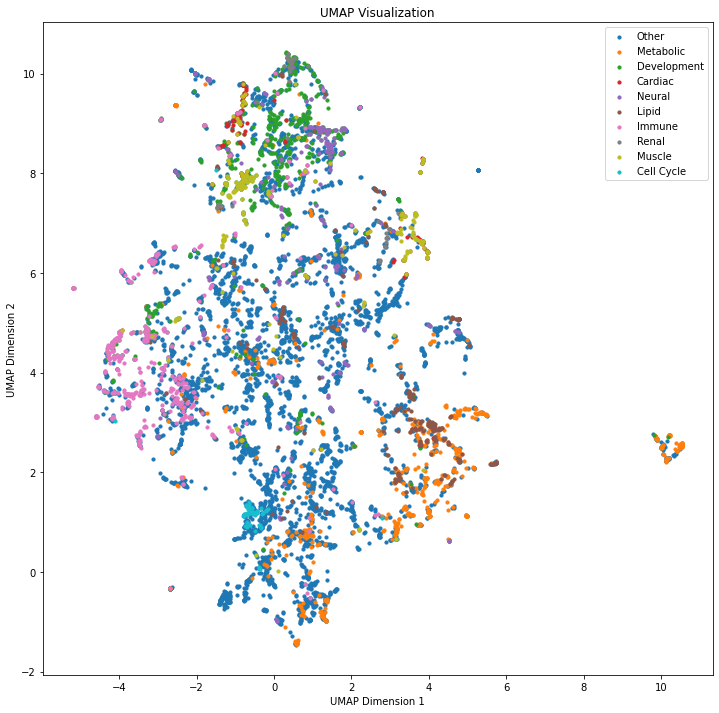

In [846]:
fig = plt.figure(figsize=(12, 12))  
fig.patch.set_facecolor('white')

plt.scatter(umap_embeddings[inds_else, 0], umap_embeddings[inds_else, 1], s=10)
plt.scatter(umap_embeddings[inds_metabolic, 0], umap_embeddings[inds_metabolic, 1], s=10)
plt.scatter(umap_embeddings[inds_dev, 0], umap_embeddings[inds_dev, 1], s=10)
plt.scatter(umap_embeddings[inds_card, 0], umap_embeddings[inds_card, 1], s=10)
plt.scatter(umap_embeddings[inds_neur, 0], umap_embeddings[inds_neur, 1], s=10)
plt.scatter(umap_embeddings[inds_lipid, 0], umap_embeddings[inds_lipid, 1], s=10)
plt.scatter(umap_embeddings[inds_immune, 0], umap_embeddings[inds_immune, 1], s=10)
plt.scatter(umap_embeddings[inds_renal, 0], umap_embeddings[inds_renal, 1], s=10)
plt.scatter(umap_embeddings[inds_muscle, 0], umap_embeddings[inds_muscle, 1], s=10)
plt.scatter(umap_embeddings[inds_cc, 0], umap_embeddings[inds_cc, 1], s=10)


plt.xlabel('UMAP Dimension 1')
plt.ylabel('UMAP Dimension 2')
plt.title('UMAP Visualization')

plt.legend(['Other', 'Metabolic', 'Development', 'Cardiac', 'Neural', 'Lipid', 'Immune', 'Renal', 'Muscle', 'Cell Cycle'])
plt.show()

In [841]:
umap_genesets[np.where(umap_embeddings[:, 0] > 8)[0]]

array(['GOBP_ADENOSINE_METABOLIC_PROCESS',
       'GOBP_ADP_BIOSYNTHETIC_PROCESS',
       'GOBP_ALLANTOIN_METABOLIC_PROCESS', 'GOBP_AMIDE_CATABOLIC_PROCESS',
       'GOBP_AMP_BIOSYNTHETIC_PROCESS', 'GOBP_AMP_CATABOLIC_PROCESS',
       'GOBP_AMP_METABOLIC_PROCESS', 'GOBP_AMP_SALVAGE',
       'GOBP_BASE_EXCISION_REPAIR',
       'GOBP_BASE_EXCISION_REPAIR_AP_SITE_FORMATION',
       'GOBP_CELLULAR_METABOLIC_COMPOUND_SALVAGE',
       'GOBP_CMP_METABOLIC_PROCESS', 'GOBP_CYTIDINE_METABOLIC_PROCESS',
       'GOBP_CYTIDINE_TO_URIDINE_EDITING', 'GOBP_DAMP_METABOLIC_PROCESS',
       'GOBP_DCMP_CATABOLIC_PROCESS',
       'GOBP_DEOXYRIBONUCLEOSIDE_CATABOLIC_PROCESS',
       'GOBP_DEOXYRIBONUCLEOSIDE_DIPHOSPHATE_METABOLIC_PROCESS',
       'GOBP_DEOXYRIBONUCLEOSIDE_METABOLIC_PROCESS',
       'GOBP_DEOXYRIBONUCLEOSIDE_MONOPHOSPHATE_BIOSYNTHETIC_PROCESS',
       'GOBP_DEOXYRIBONUCLEOSIDE_MONOPHOSPHATE_CATABOLIC_PROCESS',
       'GOBP_DEOXYRIBONUCLEOSIDE_MONOPHOSPHATE_METABOLIC_PROCESS',
       'GOBP_DE

PCA

In [1145]:
from sklearn.decomposition import PCA
import sklearn

In [1117]:
pca_inds = np.arange(len(geneset_order_sampfiltered))
# pca_inds = np.arange(1000)

pca_genesets = geneset_order_sampfiltered[pca_inds]

In [1146]:
print(sklearn.__version__)

0.24.2


In [1118]:
all_orders_log2ooe_sampfiltered[pca_inds].shape

(7747, 7000)

In [1119]:
pca = PCA(n_components=2, svd_solver='full')
pca.fit(all_orders_log2ooe_sampfiltered[pca_inds])

PCA(n_components=2, svd_solver='full')

In [1120]:
log2ooe_pca = pca.transform(all_orders_log2ooe_sampfiltered[pca_inds])

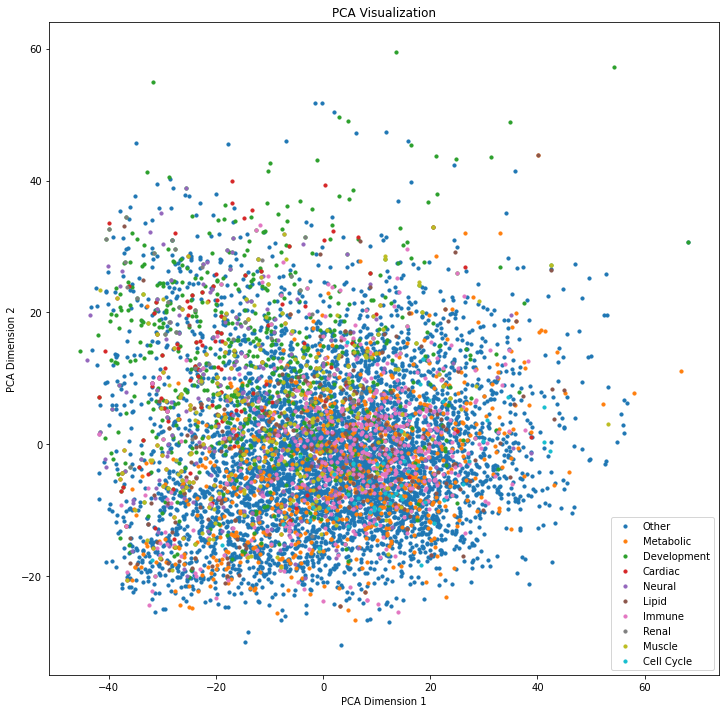

In [1125]:
fig = plt.figure(figsize=(12, 12))  
fig.patch.set_facecolor('white')

plt.scatter(log2ooe_pca[inds_else, 0], log2ooe_pca[inds_else, 1], s=10)
plt.scatter(log2ooe_pca[inds_metabolic, 0], log2ooe_pca[inds_metabolic, 1], s=10)
plt.scatter(log2ooe_pca[inds_dev, 0], log2ooe_pca[inds_dev, 1], s=10)
plt.scatter(log2ooe_pca[inds_card, 0], log2ooe_pca[inds_card, 1], s=10)
plt.scatter(log2ooe_pca[inds_neur, 0], log2ooe_pca[inds_neur, 1], s=10)
plt.scatter(log2ooe_pca[inds_lipid, 0], log2ooe_pca[inds_lipid, 1], s=10)
plt.scatter(log2ooe_pca[inds_immune, 0], log2ooe_pca[inds_immune, 1], s=10)
plt.scatter(log2ooe_pca[inds_renal, 0], log2ooe_pca[inds_renal, 1], s=10)
plt.scatter(log2ooe_pca[inds_muscle, 0], log2ooe_pca[inds_muscle, 1], s=10)
plt.scatter(log2ooe_pca[inds_cc, 0], log2ooe_pca[inds_cc, 1], s=10)


plt.xlabel('PCA Dimension 1')
plt.ylabel('PCA Dimension 2')
plt.title('PCA Visualization')

plt.legend(['Other', 'Metabolic', 'Development', 'Cardiac', 'Neural', 'Lipid', 'Immune', 'Renal', 'Muscle', 'Cell Cycle'])
plt.show()

In [1430]:
log2ooe_pca[:, 0].shape[0]

7747

In [1449]:
geneset_order_sampfiltered[np.argsort(log2ooe_pca[:, 0])][388:388*2]

array(['GOBP_ANTRAL_OVARIAN_FOLLICLE_GROWTH',
       'GOBP_POSITIVE_REGULATION_OF_EPITHELIAL_CELL_PROLIFERATION_INVOLVED_IN_LUNG_MORPHOGENESIS',
       'GOBP_EYELID_DEVELOPMENT_IN_CAMERA_TYPE_EYE',
       'GOBP_CATECHOL_CONTAINING_COMPOUND_BIOSYNTHETIC_PROCESS',
       'GOBP_RESPONSE_TO_GONADOTROPIN_RELEASING_HORMONE',
       'GOBP_HEART_GROWTH', 'GOBP_REFLEX', 'GOBP_NEURON_FATE_COMMITMENT',
       'GOBP_REGULATION_OF_CARDIAC_MUSCLE_CELL_PROLIFERATION',
       'GOBP_AUTONOMIC_NERVOUS_SYSTEM_DEVELOPMENT', 'GOBP_ANAGEN',
       'GOBP_NEGATIVE_REGULATION_OF_GRANULOCYTE_CHEMOTAXIS',
       'GOBP_PROTEIN_TRANSPORT_INTO_MEMBRANE_RAFT',
       'GOBP_DETERMINATION_OF_LIVER_LEFT_RIGHT_ASYMMETRY',
       'GOBP_REGULATION_OF_CARDIOCYTE_DIFFERENTIATION',
       'GOBP_POSITIVE_REGULATION_OF_T_HELPER_1_CELL_DIFFERENTIATION',
       'GOBP_OVIDUCT_DEVELOPMENT',
       'GOBP_NEGATIVE_REGULATION_OF_SYNAPTIC_TRANSMISSION_GLUTAMATERGIC',
       'GOBP_CARDIAC_MUSCLE_CELL_CONTRACTION',
       'GOBP_TRANSMEM

**Testing Query Regions with Spectrum**

In [1769]:
def production_post_request(coords, order, num_sim_regions):
    prod_url = 'https://explore.altius.org:5001/narration'
    post_body = {
        'location': coords,
        'factors': '[' + ','.join(np.arange(34).astype(str)) + ']',
        'roiURL': 'False',
        'scale': order,
        'queryFactorThresh': '0.5',
        'numSimilarRegions': str(num_sim_regions),
        'regionMethod': 'hilbert'
    }
    response = requests.post(prod_url, json=post_body)
    return response

def query_sim_hypergeom(region_inds, N, M, n, geneset_order, search_space_geneset_bin):
    k = np.sum(search_space_geneset_bin[region_inds], axis=0)
    inds_to_test = np.where(k)[0]

    test = hypergeom.sf(k[inds_to_test], M, n[inds_to_test], N)
    tested_genesets = geneset_order[inds_to_test]
    test = test * len(geneset_order)  # bonferroni correction
    test = np.where(test > 1, 1, test)
    return tested_genesets, inds_to_test, test

In [1770]:
# inds that are included in GPT ordering
inds_to_keep = np.where(np.isin(geneset_order, GPT_order))[0]

In [2148]:
order = 7
datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert/'
ssg_filename = 'hilbert_regions_order_{}.search_space_top_1000_no_overlap.mapped_extended_domain_GREATv4_gene_c5GOBP_genesets.bin.CT20230608.npy'.format(order)
search_space_geneset_bin_path = os.path.join(datadir, ssg_filename)

In [2149]:
search_space_geneset_bin = np.load(search_space_geneset_bin_path)[:, inds_to_keep]
print(search_space_geneset_bin.shape)
gs_region_counts = np.sum(search_space_geneset_bin, axis=0)
num_regions = search_space_geneset_bin.shape[0]
geneset_order_kept = geneset_order[inds_to_keep]

(27078, 7747)


In [2150]:
max_len = 0
for label in geneset_order_kept:
    max_len = np.max([max_len, len(label)])

In [2355]:
# query_coords = 'chr10:100141000-100166000' # pretty good, dl=1
# query_coords = 'chr4:173514000-173539000' # good at dl=7
# query_coords = 'chr14:28755875-28780934' # decent at dl=3, dl=5
# query_coords = 'chr2:88112000-88137000' # great at dl=1
query_coords = 'chr4:173522944-173539328'
gene = 'HAND2'
# query_coords = 'chr14:28753920-28770304'
# gene = 'FOXG1'
# query_coords = 'chrX:49250304-49266688'
# gene = 'FOXP3'
# query_coords = 'chr22:41484288-41549824'
# gene = 'ACO2'
# query_coords = 'chr5:173211648-173277184'
# gene='NKX2-5'




response = production_post_request(query_coords, order, num_sim_regions=20)
query_full_data = json.loads(response.text)

# find best detail level
prod_ranks = []
for i in range(len(query_full_data)):
    prod_ranks.append(query_full_data[i][0]['prod_rank'])
dl = np.argmax(prod_ranks) + 1

query_sim_region_inds = []
query_sim_region_coords = []
for i in range(1, len(query_full_data[0])):
    coord = re.split('[:-]', query_full_data[dl - 1][i]['coordinates'])
    query_sim_region_coords.append(coord)
    query_sim_region_inds.append(query_full_data[dl - 1][i]['region_ind'])
    
    
    
query_tested_gs, query_tested_gs_inds, query_tested_gs_pval = query_sim_hypergeom(
    region_inds=query_sim_region_inds, 
    N=20, 
    M=num_regions, 
    n=gs_region_counts, 
    geneset_order=geneset_order_kept,
    search_space_geneset_bin=search_space_geneset_bin
)

In [2356]:
for row in query_sim_region_coords:
    print(row[0] + '\t' + row[1] + '\t' + row[2])

chr17	80461824	80478208
chr2	219512832	219529216
chr3	128483328	128499712
chr2	44941312	44957696
chr10	7405568	7421952
chr10	8028160	8044544
chr1	156844032	156860416
chr1	24920064	24936448
chr2	44924928	44941312
chr13	35471360	35487744
chr10	123142144	123158528
chr6	35209216	35225600
chr14	105463808	105480192
chr10	8044544	8060928
chr14	105480192	105496576
chr7	45907968	45924352
chr7	20791296	20807680
chr10	123125760	123142144
chr2	45006848	45023232
chr1	75120640	75137024


In [2357]:
sort_order = np.argsort(query_tested_gs_pval)
for i, j in zip(query_tested_gs[sort_order], np.round(query_tested_gs_pval[sort_order], 10)):
    if j < 0.05:
        print(i, j)

GOBP_CELL_MATURATION 2.46212e-05
GOBP_NEUROBLAST_DIFFERENTIATION 3.39284e-05
GOBP_EAR_MORPHOGENESIS 5.96072e-05
GOBP_EPITHELIAL_CELL_MATURATION 0.0001444749
GOBP_NEUROBLAST_MIGRATION 0.0002449165
GOBP_REGULATION_OF_CELL_POPULATION_PROLIFERATION 0.0002616202
GOBP_FOREBRAIN_DORSAL_VENTRAL_PATTERN_FORMATION 0.0002929173
GOBP_MESENCHYMAL_TO_EPITHELIAL_TRANSITION 0.0003879952
GOBP_ANATOMICAL_STRUCTURE_MATURATION 0.0006485081
GOBP_EPITHELIAL_CELL_APOPTOTIC_PROCESS 0.000796762
GOBP_EMBRYONIC_ORGAN_MORPHOGENESIS 0.0015292881
GOBP_SENSORY_ORGAN_MORPHOGENESIS 0.0018874215
GOBP_PROXIMAL_DISTAL_PATTERN_FORMATION 0.0021290919
GOBP_SENSORY_ORGAN_DEVELOPMENT 0.0032351942
GOBP_REGULATION_OF_NEUROBLAST_PROLIFERATION 0.0038469283
GOBP_DEVELOPMENTAL_MATURATION 0.0042864396
GOBP_EAR_DEVELOPMENT 0.0051586478
GOBP_LENS_DEVELOPMENT_IN_CAMERA_TYPE_EYE 0.0052878605
GOBP_REGULATION_OF_KIDNEY_DEVELOPMENT 0.0054243079
GOBP_ENDOCRINE_SYSTEM_DEVELOPMENT 0.0058783551
GOBP_PITUITARY_GLAND_DEVELOPMENT 0.00664429
GOBP_

In [2358]:
query_sig_gs = query_tested_gs[np.where(query_tested_gs_pval < 0.05)[0]]
query_sig_gs_pval = query_tested_gs_pval[np.where(query_tested_gs_pval < 0.05)[0]]

In [2359]:
# sort_order = np.argsort(query_sig_gs_pval)
# for o in sort_order:
#     print(query_sig_gs[o], np.round(-np.log10(query_sig_gs_pval[o]), 4))

In [2360]:
# for i, j in zip(spectrum_gs_labels[inds_to_label], spectrum_values[inds_to_label]):
#     print('_'.join(i.split()), np.round(j, 4))

In [2361]:
# mask = spectrum_gs!=''
# for i, j in zip(spectrum_gs[mask], spectrum_value_inds):
#     if (np.where(GPT_order == i)[0][0] != j):
#         print(i)

Text(0.5, 1.15, 'GPT Order: HAND2 (chr4:173522944-173539328), Detail Level 7, Order 7')

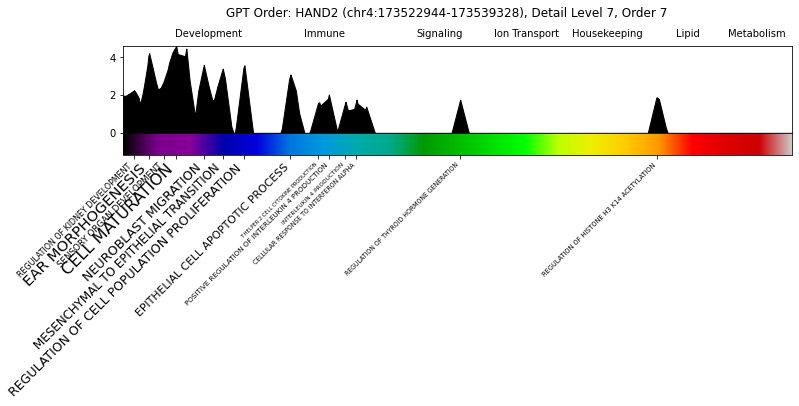

In [2362]:
# need to remove the 4 genesets we don't care about from hypergeometric test (or adjust after)
terms_to_remove = np.array(['GOBP'])
gs_order = GPT_order
window_size=100
label_padding=120
label_scale=3.5

spectrum_values = np.zeros(len(gs_order))
spectrum_gs = np.zeros(len(gs_order), dtype='<U' + str(max_len))
spectrum_value_inds = []
for gs, pval in zip(query_sig_gs, query_sig_gs_pval):
    ind = np.where(gs_order == gs)[0][0]
    spectrum_values[ind] = -np.log10(pval)
    spectrum_gs[ind] = gs
    spectrum_value_inds.append(ind)
spectrum_value_inds = np.sort(spectrum_value_inds)

# find the max over window at each position
spectrum_max = np.zeros(len(gs_order))
for i in range(len(gs_order)):
    lower_ind = np.max(
            [0,
            i - int(window_size / 2)]
        )
    upper_ind = np.min(
            [i + int(window_size / 2), 
            len(gs_order)]
        )
    test_inds = np.arange(
        lower_ind, 
        upper_ind
    )
    window_values = spectrum_values[test_inds]
    window_max = np.max(window_values)
    spectrum_max[i] = window_max
    
# average the max values over window each position to smooth
spectrum_mean = np.zeros(len(gs_order))
for i in range(len(gs_order)):
    lower_ind = np.max(
            [0,
            i - int(window_size / 2)]
        )
    upper_ind = np.min(
            [i + int(window_size / 2), 
            len(gs_order)]
        )
    test_inds = np.arange(
        lower_ind, 
        upper_ind
    )
    window_values = spectrum_max[test_inds]
    window_mean = np.mean(window_values)
    spectrum_mean[i] = window_mean
    

    
assignment_order = np.argsort(-spectrum_values)
assignment_order = assignment_order[np.isin(assignment_order, spectrum_value_inds)]

spectrum_gs_labels = np.zeros(len(gs_order), dtype='<U' + str(max_len))
for a_ind in assignment_order:
    label = spectrum_gs[a_ind]
    if (
        (label != '') & 
        (np.count_nonzero(spectrum_gs_labels[
            np.max([0, (a_ind - label_padding)]):
            np.min([(a_ind + label_padding), len(gs_order)])
        ]) == 0)
    ):
        label_l = np.array(label.split('_'))
        label_l = label_l[~np.isin(label_l, terms_to_remove)]
        label = ' '.join(label_l)
        spectrum_gs_labels[a_ind] = label
inds_to_label = np.where(spectrum_gs_labels)[0]

fig, axes = plt.subplots(2, 1, figsize=(12, 2), gridspec_kw={'height_ratios': [4, 1]})  
fig.patch.set_facecolor('white')
plt.subplots_adjust(hspace=0)
axes.ravel()

axes[0].fill_between(range(len(spectrum_mean)), spectrum_mean, color='k')
axes[0].set_xticks([])
axes[0].set_xlim([0, len(spectrum_mean)])
axes[0].set_ylim([0, np.max(spectrum_mean)])
axes[0].text(600, np.max(spectrum_mean) * 1.1, 'Development')
axes[0].text(2100, np.max(spectrum_mean) * 1.1, 'Immune')
axes[0].text(3400, np.max(spectrum_mean) * 1.1, 'Signaling')
axes[0].text(4300, np.max(spectrum_mean) * 1.1, 'Ion Transport')
axes[0].text(5200, np.max(spectrum_mean) * 1.1, 'Housekeeping')
axes[0].text(6400, np.max(spectrum_mean) * 1.1, 'Lipid')
axes[0].text(7000, np.max(spectrum_mean) * 1.1, 'Metabolism')




colors = cm.get_cmap('nipy_spectral', len(gs_order))
matplotlib.colorbar.ColorbarBase(axes[1], cmap=colors, orientation='horizontal').set_ticks(inds_to_label / len(spectrum_mean))
axes[1].set_xticklabels(spectrum_gs_labels[inds_to_label], rotation=45, ha='right')

for xlabel, size in zip(axes[1].xaxis.get_ticklabels(), spectrum_values[inds_to_label]):
    xlabel.set_fontsize(np.min([size*label_scale, 20]))

fig.suptitle('GPT Order: %s (%s), Detail Level %s, Order %s' %(gene, query_coords, dl, order), y=1.15)